In [5]:
QUICK = False            # True: 2 epochs, 1 config per experiment, seed 0 only (smoke test)
FORCE = False            # True: redo experiments that already finished
SEEDS = (0, 1, 2)
SPLIT_OVERRIDE = None    # path to your committed splits.json if you have one, else None (regenerated, deterministic)

import os, sys, json, time, glob, math, shutil, random, gc, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import torchvision.models as tvm
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
warnings.filterwarnings("ignore")

BASE = Path("/kaggle/working")
WORK = BASE / "ds6g"; CACHE = WORK / "cache"
OUT = BASE / "camera_p1"
RESULTS, EXPDIR, SPLIT_FILE = OUT / "results", OUT / "exp" / "camera", OUT / "splits" / "splits.json"
CKPT = BASE / "ckpt_camera"
for p in (WORK, CACHE, RESULTS, EXPDIR, SPLIT_FILE.parent, CKPT):
    p.mkdir(parents=True, exist_ok=True)

N_BEAMS, IMG_HW, IMG_CROP, SEED_SPLIT = 64, (256, 448), (224, 400), 0
HAS_CUDA = torch.cuda.is_available()
if not HAS_CUDA:
    raise RuntimeError("No GPU. Session options -> Accelerator -> GPU, then restart.")
DEV = "cuda"
torch.backends.cudnn.benchmark = True

hits = sorted(glob.glob("/kaggle/input/**/scenario33_dev.csv", recursive=True))
if not hits:
    raise FileNotFoundError("scenario33_dev.csv not found under /kaggle/input. Add the scenario-33 dataset as input.")
DATA_ROOT, CSV_NAME = Path(hits[0]).parent, "scenario33_dev.csv"
print("data root:", DATA_ROOT, "| QUICK:", QUICK)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

data root: /kaggle/input/datasets/haythemkrid/deepsense6g-scenario-33/scenario33 | QUICK: False


split written -> /kaggle/working/camera_p1/splits/splits.json
train  2781 samples | seqs [1, 2, 3, 5, 7, 11, 13, 14, 17, 18, 19, 20, 21]
val     602 samples | seqs [10, 12, 16]
test    598 samples | seqs [4, 8]
val: 57 distinct beams, 0.0% of samples on beams unseen in train
test: 59 distinct beams, 0.0% of samples on beams unseen in train


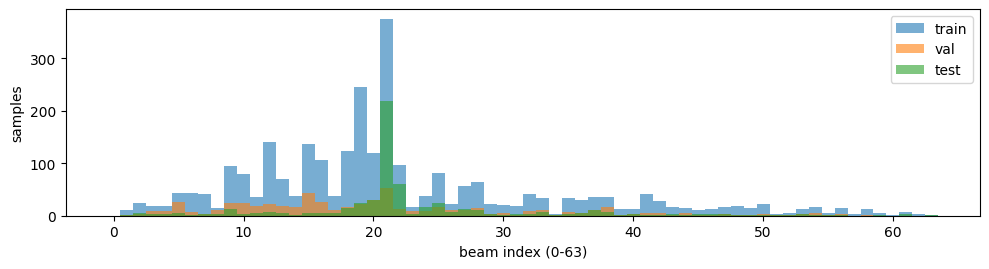

In [6]:
def build_meta():
    if (WORK / "master.csv").exists() and (CACHE / "power.npy").exists() and not FORCE:
        return
    df = pd.read_csv(DATA_ROOT / CSV_NAME, index_col=0).sort_index()
    lat0, lon0 = np.loadtxt(DATA_ROOT / df["unit1_loc"].iloc[0])
    R = 6371000
    g = np.array([np.loadtxt(DATA_ROOT / p) for p in df["unit2_loc"]])
    x = np.deg2rad(g[:, 1] - lon0) * R * np.cos(np.deg2rad(lat0))
    y = np.deg2rad(g[:, 0] - lat0) * R
    power = np.stack([np.loadtxt(DATA_ROOT / p) for p in df["unit1_pwr_60ghz"]]).astype(np.float32)
    np.save(CACHE / "power.npy", power)
    m = pd.DataFrame({
        "idx": df.index.values, "seq": df["seq_index"].values,
        "beam": df["unit1_beam"].values, "beam0": df["unit1_beam"].values - 1,
        "x_m": x, "y_m": y, "dist_m": np.hypot(x, y),
        "speed_kmph": df["unit2_spd_over_grnd_kmph"].values,
        "interpolated_gps": df["unit2_interpolated_position"].values,
        "rgb": df["unit1_rgb"].values})
    m["pos"] = m.groupby("seq").cumcount()
    assert all((g_.idx.diff().dropna() == 1).all() for _, g_ in m.groupby("seq")), "hole inside a sequence"
    m.to_csv(WORK / "master.csv", index=False)

def make_splits(m, seed=0, val_frac=0.15, test_frac=0.15, n_trials=5000):
    """Same algorithm / RNG stream as common/splits.py (unseen-beam count vectorised only)."""
    N = len(m); sizes = m.groupby("seq").size()
    beams_of = m.groupby("seq")["beam0"].apply(set).to_dict()
    arr_of = {s: g_.beam0.to_numpy() for s, g_ in m.groupby("seq")}
    rng = np.random.default_rng(seed); best, best_score = None, 1e9
    for _ in range(n_trials):
        order = rng.permutation(sizes.index.values)
        te, va, tr, nt, nv = [], [], [], 0, 0
        for s in order:
            if nt < test_frac * N: te.append(s); nt += sizes[s]
            elif nv < val_frac * N: va.append(s); nv += sizes[s]
            else: tr.append(s)
        seen = np.fromiter(set().union(*[beams_of[s] for s in tr]), dtype=np.int64)
        unseen = sum((~np.isin(arr_of[s], seen)).sum() for s in te + va) / (nt + nv)
        score = abs(nt / N - test_frac) + abs(nv / N - val_frac) + 2 * unseen
        if score < best_score: best_score, best = score, (tr, va, te)
    out = {"seed": seed, "score": float(best_score)}
    for name, seqs in zip(("train", "val", "test"), best):
        out[f"{name}_seqs"] = [int(s) for s in sorted(seqs)]
        out[name] = [int(i) for i in m[m.seq.isin(seqs)].idx]
    return out

build_meta()
M = pd.read_csv(WORK / "master.csv")
POWER = np.nan_to_num(np.load(CACHE / "power.npy"), nan=0.0)
N = len(M)

if SPLIT_OVERRIDE:
    SP = json.load(open(SPLIT_OVERRIDE)); print("using split from", SPLIT_OVERRIDE)
elif SPLIT_FILE.exists() and not FORCE:
    SP = json.load(open(SPLIT_FILE)); print("reusing", SPLIT_FILE)
else:
    SP = make_splits(M, seed=SEED_SPLIT); json.dump(SP, open(SPLIT_FILE, "w")); print("split written ->", SPLIT_FILE)
assert not (set(SP["train"]) & set(SP["val"])) and not (set(SP["train"]) & set(SP["test"])) \
    and not (set(SP["val"]) & set(SP["test"])), "split overlap!"

ROWS = {k: M.index[M.idx.isin(set(SP[k]))].to_numpy() for k in ("train", "val", "test")}
Y_NP = M.beam0.to_numpy()
for k in ROWS: print(f"{k:5s} {len(ROWS[k]):5d} samples | seqs {SP[f'{k}_seqs']}")
seen = set(Y_NP[ROWS["train"]])
for k in ("val", "test"):
    b = Y_NP[ROWS[k]]
    print(f"{k}: {len(set(b))} distinct beams, {np.mean([x not in seen for x in b]):.1%} of samples on beams unseen in train")
fig, ax = plt.subplots(figsize=(10, 2.8))
for k, c in (("train", "C0"), ("val", "C1"), ("test", "C2")):
    ax.hist(Y_NP[ROWS[k]], bins=np.arange(65) - .5, alpha=.6, label=k, color=c)
ax.set_xlabel("beam index (0-63)"); ax.set_ylabel("samples"); ax.legend(); plt.tight_layout()
plt.savefig(SPLIT_FILE.parent / "beam_hist_by_split.png", dpi=120); plt.show()

In [3]:
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

def build_camera():
    f, fb = CACHE / "camera.npy", CACHE / "bright.npy"
    if f.exists() and fb.exists() and not FORCE:
        return
    H, W = IMG_HW
    res = getattr(Image, "Resampling", Image).BILINEAR
    arr = np.zeros((N, H, W, 3), np.uint8); bright = np.zeros(N, np.float32)
    def load(r):
        a = np.asarray(Image.open(DATA_ROOT / M.rgb.iloc[r]).convert("RGB").resize((W, H), res))
        return r, a, float(a.mean())
    with ThreadPoolExecutor(4) as ex:
        for r, a, b in tqdm(ex.map(load, range(N)), total=N, desc="camera cache"):
            arr[r] = a; bright[r] = b
    np.save(f, arr); np.save(fb, bright)

build_camera()
CAM = np.load(CACHE / "camera.npy"); BRIGHT = np.load(CACHE / "bright.npy")
print("camera cache", CAM.shape, CAM.dtype, "| mean brightness (0-255):", round(float(BRIGHT.mean()), 1))

X_GPU = torch.from_numpy(CAM).to(DEV)
Y_ALL = torch.from_numpy(Y_NP).long().to(DEV)
Y_CPU, P_CPU = torch.from_numpy(Y_NP).long(), torch.from_numpy(POWER)
del CAM; gc.collect()

camera cache:   0%|          | 0/3981 [00:00<?, ?it/s]

camera cache (3981, 256, 448, 3) uint8 | mean brightness (0-255): 27.5


137

In [4]:
KS = (1, 3, 5)

def metrics_from_logits(L, Yv, Pv, ks=KS):   # identical to common/metrics.py
    top, pm = L.topk(max(ks), dim=1).indices, Pv.max(1).values
    valid = pm > 0
    res = {"n": int(len(Yv))}
    for k in ks:
        res[f"top{k}"] = (top[:, :k] == Yv[:, None]).any(1).float().mean().item()
        pk = Pv.gather(1, top[:, :k]).max(1).values.clamp(min=1e-3)
        res[f"pwr_loss_db_top{k}"] = (10 * torch.log10(pm[valid] / pk[valid])).mean().item()
        res[f"overhead_top{k}"] = k / N_BEAMS
    return res

def split_metrics(L, split):
    r = ROWS[split]; return metrics_from_logits(L, Y_CPU[r], P_CPU[r])

def val_score(m):   # mean of top1/3/5: less noisy than top1 alone on ~600 val samples
    return float(np.mean([m["top1"], m["top3"], m["top5"]]))

MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)
CH, CW = IMG_CROP

def _u(B, lo, hi, dev):
    return torch.empty(B, 1, 1, 1, device=dev).uniform_(lo, hi)

def aug_base(x):
    """Random crop + brightness/contrast (as BeamDataset). NO horizontal flip: it mirrors the beam label."""
    B, _, H, W = x.shape
    ii = torch.randint(0, H - CH + 1, (B,)).tolist(); jj = torch.randint(0, W - CW + 1, (B,)).tolist()
    x = torch.stack([x[k, :, ii[k]:ii[k] + CH, jj[k]:jj[k] + CW] for k in range(B)])
    return ((x - 0.5) * _u(B, 0.7, 1.3, x.device) + 0.5 + _u(B, -0.1, 0.1, x.device)).clamp(0, 1)

def aug_strong(x):
    """Mild zoom + small shift, wide colour jitter, gamma (night), sensor noise, cutout. No flip."""
    B, _, H, W = x.shape; dev = x.device
    z = torch.empty(B, device=dev).uniform_(0.92, 1.08)
    th = torch.zeros(B, 2, 3, device=dev)
    th[:, 0, 0] = z * CW / W; th[:, 1, 1] = z * CH / H
    th[:, 0, 2] = torch.empty(B, device=dev).uniform_(-0.08, 0.08)
    th[:, 1, 2] = torch.empty(B, device=dev).uniform_(-0.12, 0.12)
    x = F.grid_sample(x, F.affine_grid(th, (B, 3, CH, CW), align_corners=False),
                      mode="bilinear", padding_mode="border", align_corners=False)
    x = x.clamp(1e-4, 1) ** _u(B, 0.7, 1.5, dev)
    x = (x - 0.5) * _u(B, 0.6, 1.4, dev) + 0.5 + _u(B, -0.15, 0.15, dev)
    x = (x + torch.randn_like(x) * _u(B, 0.0, 0.03, dev)).clamp(0, 1)
    for k, r in enumerate(torch.rand(B).tolist()):
        if r < 0.4:
            h, w = random.randint(int(.1 * CH), int(.3 * CH)), random.randint(int(.1 * CW), int(.3 * CW))
            y0, x0 = random.randint(0, CH - h), random.randint(0, CW - w)
            x[k, :, y0:y0 + h, x0:x0 + w] = x[k].mean()
    return x

def prep_train(ib, aug):
    x = X_GPU[ib].permute(0, 3, 1, 2).float() / 255
    x = aug_strong(x) if aug == "strong" else aug_base(x)
    return ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)

def prep_eval(ib):
    x = X_GPU[ib].permute(0, 3, 1, 2).float() / 255
    H, W = x.shape[2:]; i, j = (H - CH) // 2, (W - CW) // 2
    return ((x[:, :, i:i + CH, j:j + CW] - MEAN) / STD).contiguous(memory_format=torch.channels_last)

class Net(nn.Module):
    """backbone -> embedding (penultimate) -> dropout -> Linear(64)."""
    def __init__(self, arch, pretrained=True, dropout=0.0, freeze=False):
        super().__init__()
        fn = {"resnet18": tvm.resnet18, "resnet50": tvm.resnet50,
              "efficientnet_b0": tvm.efficientnet_b0, "mobilenet_v3_large": tvm.mobilenet_v3_large}[arch]
        try:
            m = fn(weights="DEFAULT" if pretrained else None)
        except Exception as e:
            raise RuntimeError("Could not download ImageNet weights. Turn Internet ON in Session options.") from e
        if arch.startswith("resnet"): D = m.fc.in_features; m.fc = nn.Identity()
        elif arch == "efficientnet_b0": D = m.classifier[1].in_features; m.classifier = nn.Identity()
        else: D = m.classifier[0].in_features; m.classifier = nn.Identity()
        self.backbone, self.freeze, self.emb_dim = m, freeze, D
        self.drop, self.head = nn.Dropout(dropout), nn.Linear(D, N_BEAMS)
        if freeze:
            for p in self.backbone.parameters(): p.requires_grad = False
    def train(self, mode=True):
        super().train(mode)
        if self.freeze: self.backbone.eval()
        return self
    def forward(self, x, return_emb=False):
        if self.freeze:
            with torch.no_grad(): f = self.backbone(x)
        else:
            f = self.backbone(x)
        out = self.head(self.drop(f))
        return (out, f) if return_emb else out

def build(cfg, pretrained=True):
    return Net(cfg["arch"], pretrained, cfg.get("dropout", 0.0), cfg.get("freeze", False)).to(DEV).to(memory_format=torch.channels_last)

def loss_fn(out, y, cfg):
    s = cfg.get("soft_sigma", 0.0)
    if s > 0:   # beams are ordered in angle: spread target over neighbouring beams
        t = torch.exp(-(torch.arange(N_BEAMS, device=out.device)[None] - y[:, None]).float() ** 2 / (2 * s * s))
        return -((t / t.sum(1, keepdim=True)) * F.log_softmax(out, 1)).sum(1).mean()
    return F.cross_entropy(out, y, label_smoothing=cfg.get("ls", 0.0))

@torch.no_grad()
def predict(model, rows, emb=False, bs=128):
    model.eval(); Ls, Es = [], []
    for i in range(0, len(rows), bs):
        ib = torch.as_tensor(rows[i:i + bs], device=DEV)
        with torch.autocast("cuda", dtype=torch.float16):
            out, f = model(prep_eval(ib), True)
        Ls.append(out.float().cpu())
        if emb: Es.append(f.float().cpu())
    return torch.cat(Ls), (torch.cat(Es) if emb else None)

def count_params(model, trainable=False):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable))

def _scaler():
    try: return torch.amp.GradScaler("cuda")
    except Exception: return torch.cuda.amp.GradScaler()

def train_model(cfg, seed, tag=""):
    """Train on train split, keep best-val epoch. Test is NOT touched here."""
    seed_everything(seed); t0 = time.time()
    model = build(cfg)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=cfg["wd"])
    E = 2 if QUICK else cfg["epochs"]; bs = cfg["bs"]
    tr = torch.as_tensor(ROWS["train"], device=DEV); n = len(tr); spe = max(1, n // bs)
    total, warm = E * spe, spe
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = _scaler(); hist, best = [], (-1, None, None, None)
    Yv, Pv = Y_CPU[ROWS["val"]], P_CPU[ROWS["val"]]
    for ep in range(E):
        model.train(); perm = torch.randperm(n, device=DEV); run = 0.0
        for b in range(spe):
            ib = tr[perm[b * bs:(b + 1) * bs]]
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(prep_train(ib, cfg["aug"]))
            loss = loss_fn(out.float(), Y_ALL[ib], cfg)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sched.step(); run += loss.item()
        Lv, _ = predict(model, ROWS["val"]); mv = metrics_from_logits(Lv, Yv, Pv)
        h = {"epoch": ep + 1, "train_loss": run / spe, "val_loss": F.cross_entropy(Lv, Yv).item(),
             "val_top1": mv["top1"], "val_top3": mv["top3"], "val_top5": mv["top5"], "val_score": val_score(mv)}
        hist.append(h)
        if h["val_score"] > best[0]:
            best = (h["val_score"], ep + 1, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, mv)
        print(f"  {tag} ep{ep + 1:02d}/{E} loss {h['train_loss']:.3f} | val loss {h['val_loss']:.3f} "
              f"top1 {mv['top1']:.3f} top3 {mv['top3']:.3f} top5 {mv['top5']:.3f}", flush=True)
    out = dict(state=best[2], best_epoch=best[1], val=best[3], val_score=best[0], history=hist,
               secs=time.time() - t0, params=count_params(model), trainable=count_params(model, True))
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    return out

In [5]:
def save_results(exp_id, seed, metrics, config, ckpt_path=None, params=None, train_time_s=None, extra=None, arrays=None):
    d = RESULTS / exp_id; d.mkdir(parents=True, exist_ok=True)
    rec = {"exp_id": exp_id, "seed": seed, **metrics, "params": params, "train_time_s": train_time_s,
           "ckpt": str(ckpt_path), **(extra or {}), "config": config}
    json.dump(rec, open(d / f"seed{seed}.json", "w"), indent=1, default=str)
    for name, arr in (arrays or {}).items():
        np.save(d / f"seed{seed}_{name}.npy", arr.numpy() if torch.is_tensor(arr) else arr)
    row = pd.DataFrame([{k: v for k, v in rec.items() if k != "config"}])
    f = RESULTS / "all_results.csv"
    if f.exists():
        old = pd.read_csv(f); row = pd.concat([old[~((old.exp_id == exp_id) & (old.seed == seed))], row], ignore_index=True)
    row.to_csv(f, index=False)

def finalize(exp_id, seed, cfg, out, n_tuned):
    """Rebuild best-val checkpoint, predict everything once, evaluate TEST once, save logits + embeddings."""
    model = build(cfg, pretrained=False); model.load_state_dict(out["state"])
    Lall, Eall = predict(model, np.arange(N), emb=True)
    mt, mv = split_metrics(Lall[ROWS["test"]], "test"), split_metrics(Lall[ROWS["val"]], "val")
    ck = CKPT / f"{exp_id}_seed{seed}.pt"; torch.save(out["state"], ck)
    E16 = Eall.numpy().astype(np.float16)
    arrays = {"val_logits": Lall[ROWS["val"]], "test_logits": Lall[ROWS["test"]], "train_logits": Lall[ROWS["train"]],
              "embeddings": E16,   # (N, D), master.csv row order, eval mode, center crop
              "train_embeddings": E16[ROWS["train"]], "val_embeddings": E16[ROWS["val"]], "test_embeddings": E16[ROWS["test"]]}
    extra = {**{f"val_{k}": v for k, v in mv.items() if k.startswith("top")}, "val_score": out["val_score"],
             "best_epoch": out["best_epoch"], "trainable_params": out["trainable"], "n_configs_tried": n_tuned}
    save_results(exp_id, seed, mt, cfg, ck, out["params"], out["secs"], extra, arrays)
    json.dump(out["history"], open(RESULTS / exp_id / f"seed{seed}_history.json", "w"))
    print(f"[{exp_id} seed {seed}] TEST top1 {mt['top1']:.3f} top3 {mt['top3']:.3f} top5 {mt['top5']:.3f} "
          f"| val_score {out['val_score']:.3f} | best ep {out['best_epoch']} | {out['secs'] / 60:.1f} min", flush=True)
    del model; gc.collect()

EXPERIMENTS = {
  "CAM-E1": dict(title="ResNet18 (ImageNet), frozen backbone, linear head",
    configs=[dict(arch="resnet18", freeze=True, lr=lr, wd=1e-2, epochs=30, bs=32, aug="base") for lr in (1e-3, 3e-3, 1e-2)]),
  "CAM-E2": dict(title="ResNet50 (ImageNet), full fine-tune",
    configs=[dict(arch="resnet50", lr=1e-4, wd=1e-2, epochs=20, bs=32, aug="base"),
             dict(arch="resnet50", lr=3e-4, wd=1e-2, epochs=20, bs=32, aug="base"),
             dict(arch="resnet50", lr=1e-4, wd=1e-2, epochs=20, bs=32, aug="base", ls=0.1)]),
  "CAM-E3": dict(title="EfficientNet-B0 / MobileNetV3-L + strong augmentation",
    configs=[dict(arch="efficientnet_b0", lr=5e-4, wd=1e-2, epochs=30, bs=32, aug="strong", ls=0.1, dropout=0.3),
             dict(arch="efficientnet_b0", lr=1e-3, wd=1e-2, epochs=30, bs=32, aug="strong", ls=0.1, dropout=0.3),
             dict(arch="efficientnet_b0", lr=5e-4, wd=1e-2, epochs=30, bs=32, aug="strong", soft_sigma=1.5, dropout=0.3),
             dict(arch="mobilenet_v3_large", lr=1e-3, wd=1e-2, epochs=30, bs=32, aug="strong", ls=0.1, dropout=0.3)]),
}

def run_experiment(exp_id):
    spec = EXPERIMENTS[exp_id]; d = RESULTS / exp_id; d.mkdir(parents=True, exist_ok=True)
    if (d / "done.json").exists() and not FORCE and json.load(open(d / "done.json")).get("quick") == QUICK:
        print(f"{exp_id} already done (FORCE=True to redo)"); return
    configs = spec["configs"][:1] if QUICK else spec["configs"]
    seeds = SEEDS[:1] if QUICK else SEEDS
    print(f"===== {exp_id}: {spec['title']} | {len(configs)} configs tuned on val (seed 0) =====")
    tuned, outs = [], []
    for i, cfg in enumerate(configs):
        print(f"-- config {i}: {cfg}")
        o = train_model(cfg, 0, f"{exp_id}/c{i}"); outs.append(o)
        tuned.append({"cfg_id": i, **cfg, "val_score": o["val_score"], "val_top1": o["val"]["top1"],
                      "val_top3": o["val"]["top3"], "val_top5": o["val"]["top5"], "best_epoch": o["best_epoch"],
                      "minutes": o["secs"] / 60})
    bi = int(np.argmax([t["val_score"] for t in tuned])); cfg = configs[bi]
    pd.DataFrame(tuned).to_csv(d / "tuning.csv", index=False)
    json.dump({"chosen": bi, "table": tuned}, open(d / "tuning.json", "w"), indent=1)
    print(f"-- chosen config {bi} (val_score {tuned[bi]['val_score']:.3f}); seeds {list(seeds)}")
    for s in seeds:
        finalize(exp_id, s, cfg, outs[bi] if s == 0 else train_model(cfg, s, f"{exp_id}/s{s}"), len(configs))
    json.dump({"chosen_cfg": bi, "config": cfg, "seeds": list(seeds), "quick": QUICK}, open(d / "done.json", "w"))
    del outs; gc.collect(); torch.cuda.empty_cache()

In [6]:
run_experiment("CAM-E1")

===== CAM-E1: ResNet18 (ImageNet), frozen backbone, linear head | 3 configs tuned on val (seed 0) =====
-- config 0: {'arch': 'resnet18', 'freeze': True, 'lr': 0.001, 'wd': 0.01, 'epochs': 30, 'bs': 32, 'aug': 'base'}
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 175MB/s] 


  CAM-E1/c0 ep01/30 loss 3.789 | val loss 3.844 top1 0.086 top3 0.208 top5 0.284
  CAM-E1/c0 ep02/30 loss 3.524 | val loss 3.824 top1 0.061 top3 0.184 top5 0.239
  CAM-E1/c0 ep03/30 loss 3.416 | val loss 3.750 top1 0.037 top3 0.158 top5 0.251
  CAM-E1/c0 ep04/30 loss 3.320 | val loss 3.764 top1 0.060 top3 0.173 top5 0.276
  CAM-E1/c0 ep05/30 loss 3.248 | val loss 3.868 top1 0.051 top3 0.138 top5 0.226
  CAM-E1/c0 ep06/30 loss 3.190 | val loss 3.750 top1 0.063 top3 0.163 top5 0.259
  CAM-E1/c0 ep07/30 loss 3.134 | val loss 3.798 top1 0.053 top3 0.176 top5 0.224
  CAM-E1/c0 ep08/30 loss 3.099 | val loss 3.804 top1 0.048 top3 0.159 top5 0.274
  CAM-E1/c0 ep09/30 loss 3.068 | val loss 3.789 top1 0.068 top3 0.166 top5 0.248
  CAM-E1/c0 ep10/30 loss 3.039 | val loss 3.769 top1 0.063 top3 0.178 top5 0.251
  CAM-E1/c0 ep11/30 loss 2.999 | val loss 3.822 top1 0.071 top3 0.188 top5 0.282
  CAM-E1/c0 ep12/30 loss 2.981 | val loss 3.845 top1 0.076 top3 0.153 top5 0.261
  CAM-E1/c0 ep13/30 loss 2.9

In [7]:
run_experiment("CAM-E2")

===== CAM-E2: ResNet50 (ImageNet), full fine-tune | 3 configs tuned on val (seed 0) =====
-- config 0: {'arch': 'resnet50', 'lr': 0.0001, 'wd': 0.01, 'epochs': 20, 'bs': 32, 'aug': 'base'}
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 225MB/s]


  CAM-E2/c0 ep01/20 loss 3.851 | val loss 3.827 top1 0.085 top3 0.178 top5 0.287
  CAM-E2/c0 ep02/20 loss 2.998 | val loss 3.510 top1 0.108 top3 0.243 top5 0.334
  CAM-E2/c0 ep03/20 loss 2.427 | val loss 3.541 top1 0.138 top3 0.336 top5 0.407
  CAM-E2/c0 ep04/20 loss 2.037 | val loss 3.288 top1 0.141 top3 0.352 top5 0.467
  CAM-E2/c0 ep05/20 loss 1.817 | val loss 3.424 top1 0.164 top3 0.350 top5 0.460
  CAM-E2/c0 ep06/20 loss 1.667 | val loss 3.394 top1 0.173 top3 0.389 top5 0.478
  CAM-E2/c0 ep07/20 loss 1.554 | val loss 3.373 top1 0.181 top3 0.382 top5 0.500
  CAM-E2/c0 ep08/20 loss 1.452 | val loss 3.739 top1 0.186 top3 0.402 top5 0.498
  CAM-E2/c0 ep09/20 loss 1.378 | val loss 3.537 top1 0.208 top3 0.419 top5 0.517
  CAM-E2/c0 ep10/20 loss 1.295 | val loss 3.586 top1 0.208 top3 0.432 top5 0.512
  CAM-E2/c0 ep11/20 loss 1.246 | val loss 3.631 top1 0.206 top3 0.395 top5 0.502
  CAM-E2/c0 ep12/20 loss 1.176 | val loss 3.521 top1 0.211 top3 0.415 top5 0.508
  CAM-E2/c0 ep13/20 loss 1.1

In [8]:
run_experiment("CAM-E3")

===== CAM-E3: EfficientNet-B0 / MobileNetV3-L + strong augmentation | 4 configs tuned on val (seed 0) =====
-- config 0: {'arch': 'efficientnet_b0', 'lr': 0.0005, 'wd': 0.01, 'epochs': 30, 'bs': 32, 'aug': 'strong', 'ls': 0.1, 'dropout': 0.3}
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 154MB/s]


  CAM-E3/c0 ep01/30 loss 3.791 | val loss 4.534 top1 0.105 top3 0.204 top5 0.306
  CAM-E3/c0 ep02/30 loss 3.056 | val loss 3.667 top1 0.113 top3 0.286 top5 0.377
  CAM-E3/c0 ep03/30 loss 2.639 | val loss 3.133 top1 0.199 top3 0.429 top5 0.545
  CAM-E3/c0 ep04/30 loss 2.412 | val loss 3.053 top1 0.181 top3 0.447 top5 0.555
  CAM-E3/c0 ep05/30 loss 2.265 | val loss 3.304 top1 0.178 top3 0.425 top5 0.540
  CAM-E3/c0 ep06/30 loss 2.190 | val loss 3.047 top1 0.176 top3 0.407 top5 0.576
  CAM-E3/c0 ep07/30 loss 2.126 | val loss 2.875 top1 0.218 top3 0.472 top5 0.616
  CAM-E3/c0 ep08/30 loss 2.060 | val loss 2.749 top1 0.249 top3 0.507 top5 0.646
  CAM-E3/c0 ep09/30 loss 2.032 | val loss 2.755 top1 0.234 top3 0.517 top5 0.623
  CAM-E3/c0 ep10/30 loss 1.973 | val loss 2.823 top1 0.269 top3 0.510 top5 0.616
  CAM-E3/c0 ep11/30 loss 1.927 | val loss 2.786 top1 0.262 top3 0.482 top5 0.638
  CAM-E3/c0 ep12/30 loss 1.896 | val loss 2.862 top1 0.256 top3 0.518 top5 0.625
  CAM-E3/c0 ep13/30 loss 1.8

100%|██████████| 21.1M/21.1M [00:00<00:00, 153MB/s]


  CAM-E3/c3 ep01/30 loss 3.671 | val loss 4.915 top1 0.071 top3 0.193 top5 0.246
  CAM-E3/c3 ep02/30 loss 2.965 | val loss 4.469 top1 0.083 top3 0.191 top5 0.271
  CAM-E3/c3 ep03/30 loss 2.633 | val loss 4.337 top1 0.035 top3 0.068 top5 0.101
  CAM-E3/c3 ep04/30 loss 2.413 | val loss 3.510 top1 0.154 top3 0.331 top5 0.450
  CAM-E3/c3 ep05/30 loss 2.332 | val loss 3.227 top1 0.206 top3 0.434 top5 0.565
  CAM-E3/c3 ep06/30 loss 2.230 | val loss 3.276 top1 0.194 top3 0.399 top5 0.525
  CAM-E3/c3 ep07/30 loss 2.170 | val loss 3.364 top1 0.194 top3 0.402 top5 0.518
  CAM-E3/c3 ep08/30 loss 2.122 | val loss 3.141 top1 0.219 top3 0.440 top5 0.575
  CAM-E3/c3 ep09/30 loss 2.077 | val loss 2.977 top1 0.226 top3 0.485 top5 0.598
  CAM-E3/c3 ep10/30 loss 2.018 | val loss 2.913 top1 0.218 top3 0.480 top5 0.598
  CAM-E3/c3 ep11/30 loss 1.983 | val loss 3.047 top1 0.216 top3 0.462 top5 0.580
  CAM-E3/c3 ep12/30 loss 1.946 | val loss 3.088 top1 0.219 top3 0.465 top5 0.565
  CAM-E3/c3 ep13/30 loss 1.9

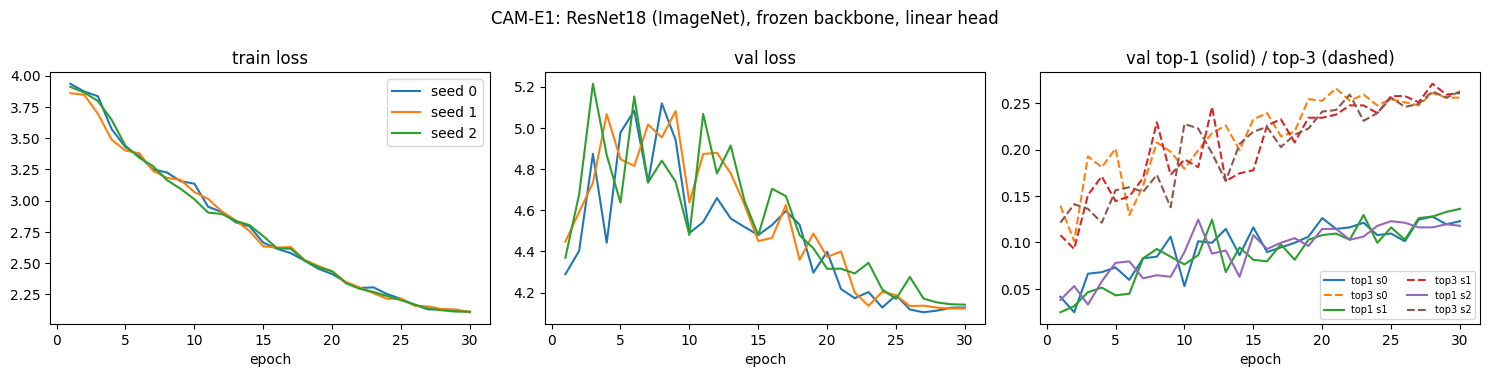

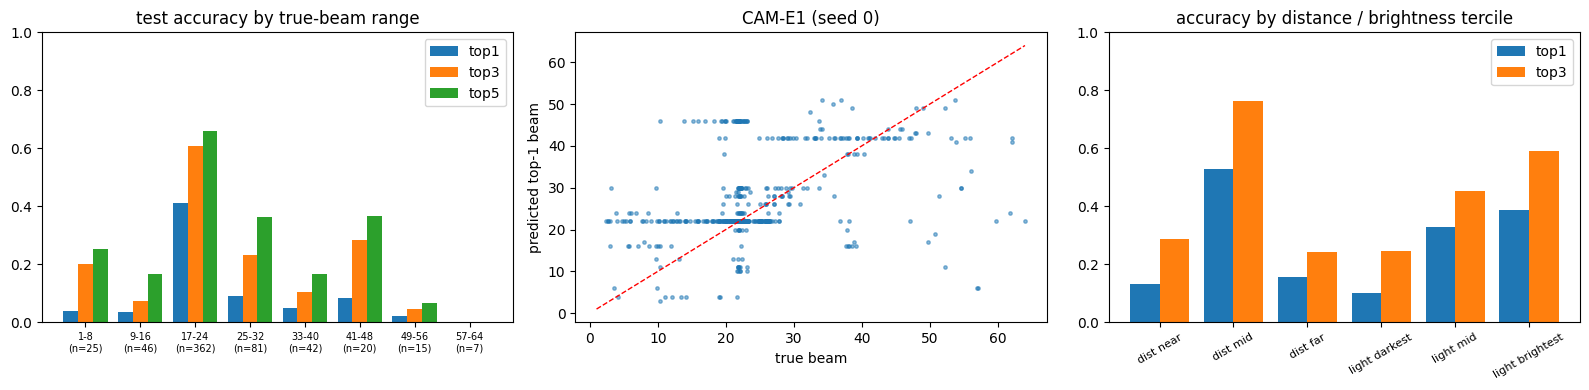

# CAM-E1: ResNet18 (ImageNet), frozen backbone, linear head
- **Hypothesis:** Frozen ImageNet features carry little beam information from night images; a linear probe sets the floor every later camera model must beat.
- **Change:** {'arch': 'resnet18', 'freeze': True, 'lr': 0.01, 'wd': 0.01, 'epochs': 30, 'bs': 32, 'aug': 'base'}. Chosen on val (mean of top1/3/5) out of 3 configs, see `tuning.csv`. Seeds [0, 1, 2]; best-val epoch kept; no horizontal flip.
- **Result (test, mean ± std over 3 seeds):** top-1 0.272 ± 0.010 | top-3 0.431 ± 0.017 | top-5 0.498 ± 0.019 | power loss @top-3 0.47 dB | params 11,209,344 (trainable 32,832) | 1.2 min/run.
- **Failure:** weakest beam range 49-56 (top-3 0.04, n=15), strongest 17-24 (top-3 0.61, n=362). Mean |beam error| of top-1 = 5.9 beams. Far users top-3 0.24 vs near 0.29; darkest frames 0.25 vs brightest 0.59. See `failure_analysis.png/csv`.
- **Next:** Unfreeze the backbone (CAM-E2).



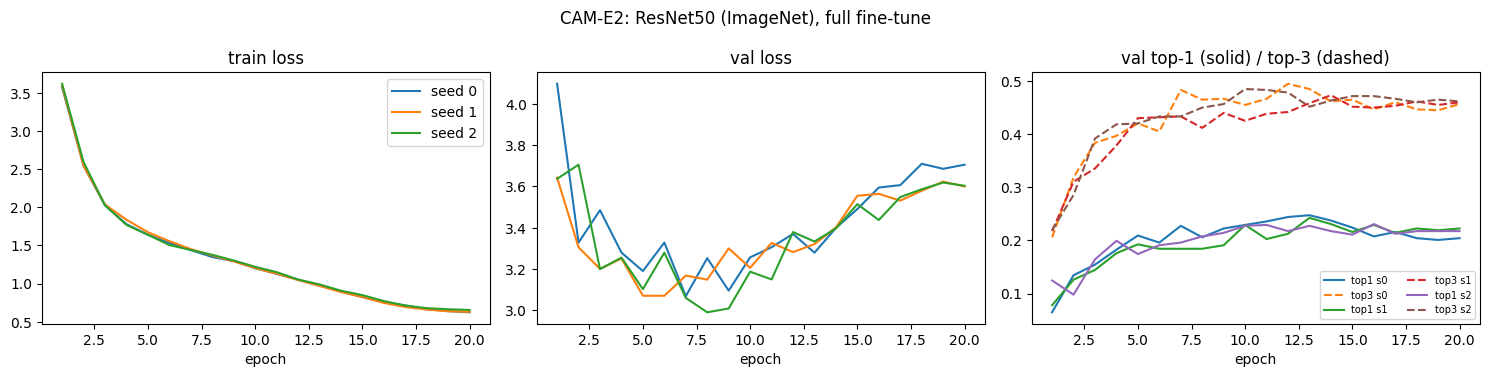

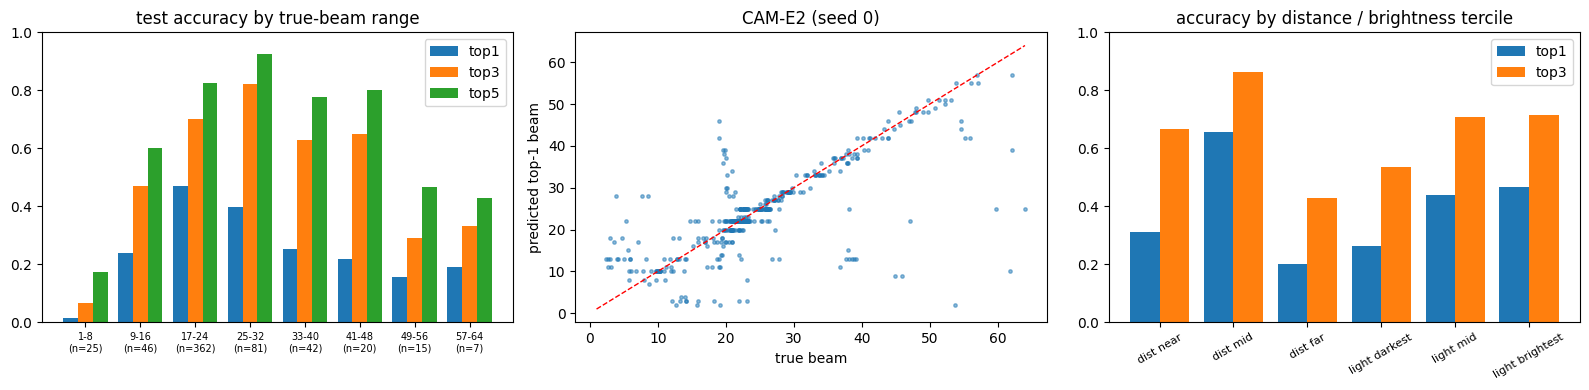

# CAM-E2: ResNet50 (ImageNet), full fine-tune
- **Hypothesis:** Fine-tuning a high-capacity backbone adapts features to the user's position/size in the frame and should clearly beat the frozen probe.
- **Change:** {'arch': 'resnet50', 'lr': 0.0003, 'wd': 0.01, 'epochs': 20, 'bs': 32, 'aug': 'base'}. Chosen on val (mean of top1/3/5) out of 3 configs, see `tuning.csv`. Seeds [0, 1, 2]; best-val epoch kept; no horizontal flip.
- **Result (test, mean ± std over 3 seeds):** top-1 0.389 ± 0.127 | top-3 0.652 ± 0.085 | top-5 0.777 ± 0.028 | power loss @top-3 0.29 dB | params 23,639,168 (trainable 23,639,168) | 5.4 min/run.
- **Failure:** weakest beam range 1-8 (top-3 0.07, n=25), strongest 25-32 (top-3 0.82, n=81). Mean |beam error| of top-1 = 3.0 beams. Far users top-3 0.43 vs near 0.66; darkest frames 0.54 vs brightest 0.71. See `failure_analysis.png/csv`.
- **Next:** Smaller model, stronger augmentation, ordinal-aware targets (CAM-E3); with ~2.8k frames from few sequences, overfitting is t

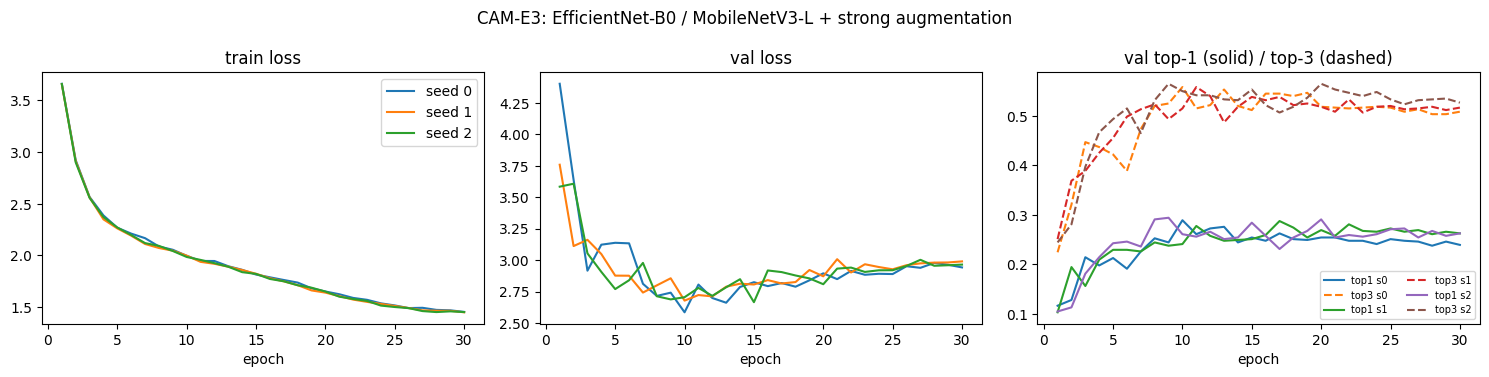

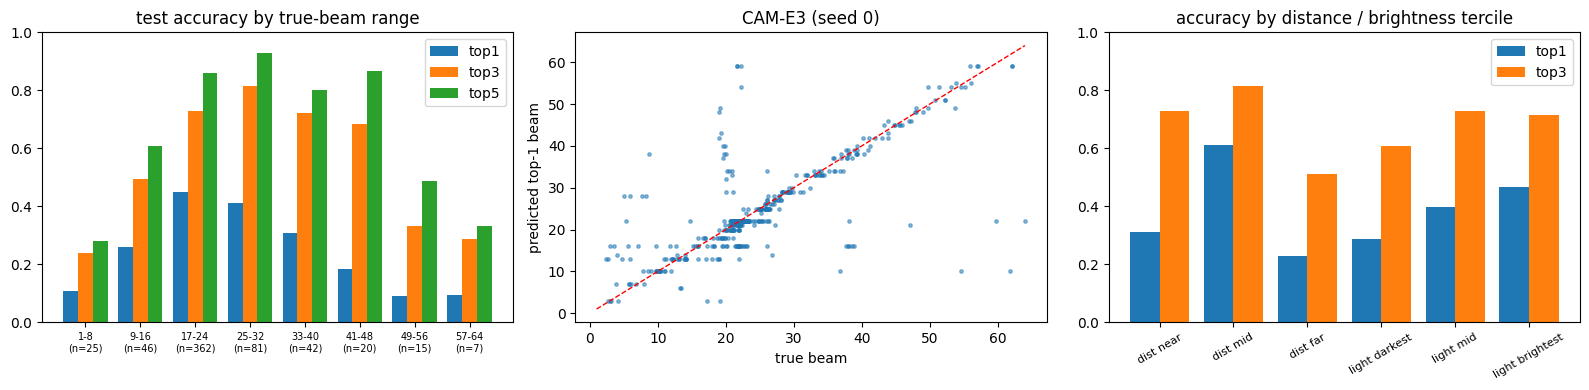

# CAM-E3: EfficientNet-B0 / MobileNetV3-L + strong augmentation
- **Hypothesis:** A lighter network with strong photometric/geometric augmentation generalises better across sequences than ResNet50 on this small night-only set.
- **Change:** {'arch': 'efficientnet_b0', 'lr': 0.001, 'wd': 0.01, 'epochs': 30, 'bs': 32, 'aug': 'strong', 'ls': 0.1, 'dropout': 0.3}. Chosen on val (mean of top1/3/5) out of 4 configs, see `tuning.csv`. Seeds [0, 1, 2]; best-val epoch kept; no horizontal flip.
- **Result (test, mean ± std over 3 seeds):** top-1 0.384 ± 0.114 | top-3 0.684 ± 0.094 | top-5 0.805 ± 0.017 | power loss @top-3 0.25 dB | params 4,089,532 (trainable 4,089,532) | 5.8 min/run.
- **Failure:** weakest beam range 1-8 (top-3 0.24, n=25), strongest 25-32 (top-3 0.81, n=81). Mean |beam error| of top-1 = 3.0 beams. Far users top-3 0.51 vs near 0.73; darkest frames 0.61 vs brightest 0.71. See `failure_analysis.png/csv`.
- **Next:** Feed saved logits/embeddings into fusion (F1 late fusion) and co

In [9]:
def runs(exp_id):
    return sorted(int(p.stem[4:]) for p in (RESULTS / exp_id).glob("seed[0-9].json"))

def plot_curves(exp_id):
    d = RESULTS / exp_id; fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for s in runs(exp_id):
        h = pd.DataFrame(json.load(open(d / f"seed{s}_history.json")))
        ax[0].plot(h.epoch, h.train_loss, label=f"seed {s}"); ax[1].plot(h.epoch, h.val_loss, label=f"seed {s}")
        ax[2].plot(h.epoch, h.val_top1, "-", label=f"top1 s{s}"); ax[2].plot(h.epoch, h.val_top3, "--", label=f"top3 s{s}")
    for a, t in zip(ax, ("train loss", "val loss", "val top-1 (solid) / top-3 (dashed)")): a.set_title(t); a.set_xlabel("epoch")
    ax[0].legend(); ax[2].legend(fontsize=7, ncol=2); fig.suptitle(f"{exp_id}: {EXPERIMENTS[exp_id]['title']}")
    plt.tight_layout(); plt.savefig(d / "training_curves.png", dpi=120); plt.show()

def analyze_failures(exp_id):
    d = RESULTS / exp_id; r = ROWS["test"]; Yt = Y_NP[r]; S = runs(exp_id)
    hit = {k: np.zeros(len(r)) for k in KS}; err = np.zeros(len(r)); pred0 = None
    for s in S:
        top = torch.from_numpy(np.load(d / f"seed{s}_test_logits.npy")).topk(5, 1).indices.numpy()
        for k in KS: hit[k] += (top[:, :k] == Yt[:, None]).any(1) / len(S)
        err += np.abs(top[:, 0] - Yt) / len(S)
        if pred0 is None: pred0 = top[:, 0]
    q = lambda v, names: pd.qcut(pd.Series(v).rank(method="first"), 3, labels=names)
    df = pd.DataFrame({"beam_group": [f"{g * 8 + 1}-{g * 8 + 8}" for g in Yt // 8], "g": Yt // 8,
                       "top1": hit[1], "top3": hit[3], "top5": hit[5], "abs_beam_err_top1": err,
                       "distance": q(M.dist_m.to_numpy()[r], ["near", "mid", "far"]),
                       "brightness": q(BRIGHT[r], ["darkest", "mid", "brightest"])})
    cols = ["top1", "top3", "top5", "abs_beam_err_top1"]
    gb = df.groupby(["g", "beam_group"]).agg(n=("top1", "size"), **{c: (c, "mean") for c in cols}).reset_index().drop(columns="g")
    gd = df.groupby("distance").agg(n=("top1", "size"), **{c: (c, "mean") for c in cols}).reset_index()
    gl = df.groupby("brightness").agg(n=("top1", "size"), **{c: (c, "mean") for c in cols}).reset_index()
    pd.concat([gb.assign(by="beam_group").rename(columns={"beam_group": "bin"}),
               gd.assign(by="distance").rename(columns={"distance": "bin"}),
               gl.assign(by="brightness").rename(columns={"brightness": "bin"})]).to_csv(d / "failure_analysis.csv", index=False)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    xs = np.arange(len(gb)); w = .27
    for j, k in enumerate(("top1", "top3", "top5")): ax[0].bar(xs + (j - 1) * w, gb[k], w, label=k)
    ax[0].set_xticks(xs); ax[0].set_xticklabels([f"{b}\n(n={n})" for b, n in zip(gb.beam_group, gb.n)], fontsize=7)
    ax[0].set_title("test accuracy by true-beam range"); ax[0].legend(); ax[0].set_ylim(0, 1)
    jit = np.random.default_rng(0).normal(0, .25, len(Yt))
    ax[1].scatter(Yt + 1 + jit, pred0 + 1, s=6, alpha=.5); ax[1].plot([1, 64], [1, 64], "r--", lw=1)
    ax[1].set_xlabel("true beam"); ax[1].set_ylabel("predicted top-1 beam"); ax[1].set_title(f"{exp_id} (seed {S[0]})")
    gg = pd.concat([gd.rename(columns={"distance": "bin"}), gl.rename(columns={"brightness": "bin"})], ignore_index=True)
    xs = np.arange(len(gg))
    for j, k in enumerate(("top1", "top3")): ax[2].bar(xs + (j - .5) * .4, gg[k], .4, label=k)
    ax[2].set_xticks(xs); ax[2].set_xticklabels([f"{('dist ' if i < 3 else 'light ')}{b}" for i, b in enumerate(gg['bin'])], rotation=30, fontsize=8)
    ax[2].set_title("accuracy by distance / brightness tercile"); ax[2].legend(); ax[2].set_ylim(0, 1)
    plt.tight_layout(); plt.savefig(d / "failure_analysis.png", dpi=120); plt.show()
    return gb, gd, gl

NOTES = {
 "CAM-E1": ("Frozen ImageNet features carry little beam information from night images; a linear probe sets the floor every later camera model must beat.",
            "Unfreeze the backbone (CAM-E2)."),
 "CAM-E2": ("Fine-tuning a high-capacity backbone adapts features to the user's position/size in the frame and should clearly beat the frozen probe.",
            "Smaller model, stronger augmentation, ordinal-aware targets (CAM-E3); with ~2.8k frames from few sequences, overfitting is the main risk."),
 "CAM-E3": ("A lighter network with strong photometric/geometric augmentation generalises better across sequences than ResNet50 on this small night-only set.",
            "Feed saved logits/embeddings into fusion (F1 late fusion) and compare against the GPS baseline."),
}

def write_notes(exp_id, gb, gd, gl):
    d = RESULTS / exp_id; S = runs(exp_id); R = pd.DataFrame([json.load(open(d / f"seed{s}.json")) for s in S])
    cfg = R.config.iloc[0]
    ms = lambda c: f"{R[c].mean():.3f} ± {R[c].std(ddof=1) if len(R) > 1 else float('nan'):.3f}"
    g = gb[gb.n >= 15]
    if len(g) == 0: g = gb
    wk = g.sort_values("top3").iloc[0]; bt = g.sort_values("top3").iloc[-1]
    gd_, gl_ = gd.set_index("distance"), gl.set_index("brightness")
    far, near, dk, br = gd_.loc["far"], gd_.loc["near"], gl_.loc["darkest"], gl_.loc["brightest"]
    tun = pd.read_csv(d / "tuning.csv"); mae = gb.abs_beam_err_top1.mul(gb.n).sum() / gb.n.sum()
    txt = f"""# {exp_id}: {EXPERIMENTS[exp_id]['title']}
- **Hypothesis:** {NOTES[exp_id][0]}
- **Change:** {cfg}. Chosen on val (mean of top1/3/5) out of {len(tun)} configs, see `tuning.csv`. Seeds {S}; best-val epoch kept; no horizontal flip.
- **Result (test, mean ± std over {len(S)} seeds):** top-1 {ms('top1')} | top-3 {ms('top3')} | top-5 {ms('top5')} | power loss @top-3 {R.pwr_loss_db_top3.mean():.2f} dB | params {int(R.params.iloc[0]):,} (trainable {int(R.trainable_params.iloc[0]):,}) | {R.train_time_s.mean() / 60:.1f} min/run.
- **Failure:** weakest beam range {wk.beam_group} (top-3 {wk.top3:.2f}, n={int(wk.n)}), strongest {bt.beam_group} (top-3 {bt.top3:.2f}, n={int(bt.n)}). Mean |beam error| of top-1 = {mae:.1f} beams. Far users top-3 {far.top3:.2f} vs near {near.top3:.2f}; darkest frames {dk.top3:.2f} vs brightest {br.top3:.2f}. See `failure_analysis.png/csv`.
- **Next:** {NOTES[exp_id][1]}
"""
    (EXPDIR / exp_id).mkdir(parents=True, exist_ok=True)
    (EXPDIR / exp_id / "notes.md").write_text(txt); (d / "notes.md").write_text(txt)
    print(txt)

for e in EXPERIMENTS:
    if (RESULTS / e / "done.json").exists():
        plot_curves(e); gb, gd, gl = analyze_failures(e); write_notes(e, gb, gd, gl)

,experiment,model,seeds,top1,top3,top5,pwr_loss_dB@top1,pwr_loss_dB@top3,pwr_loss_dB@top5,overhead@1/3/5,params,train_min/run,val_score
0,CAM-E1,"ResNet18 (ImageNet), frozen backbone, linear head",3,0.272 ± 0.010,0.431 ± 0.017,0.498 ± 0.019,1.29,0.47,0.32,"1/64, 3/64, 5/64","11,209,344",1.2,0.249
1,CAM-E2,"ResNet50 (ImageNet), full fine-tune",3,0.389 ± 0.127,0.652 ± 0.085,0.777 ± 0.028,0.61,0.29,0.18,"1/64, 3/64, 5/64","23,639,168",5.4,0.439
2,CAM-E3,EfficientNet-B0 / MobileNetV3-L + strong augme...,3,0.384 ± 0.114,0.684 ± 0.094,0.805 ± 0.017,0.51,0.25,0.15,"1/64, 3/64, 5/64","4,089,532",5.8,0.508
3,baseline,random,-,0.016,0.047,0.078,,,,,,,
4,baseline,majority beam,-,0.366,0.418,0.453,,,,,,,
5,baseline,exhaustive sweep (64),-,1.000,1.000,1.000,,,,,,,


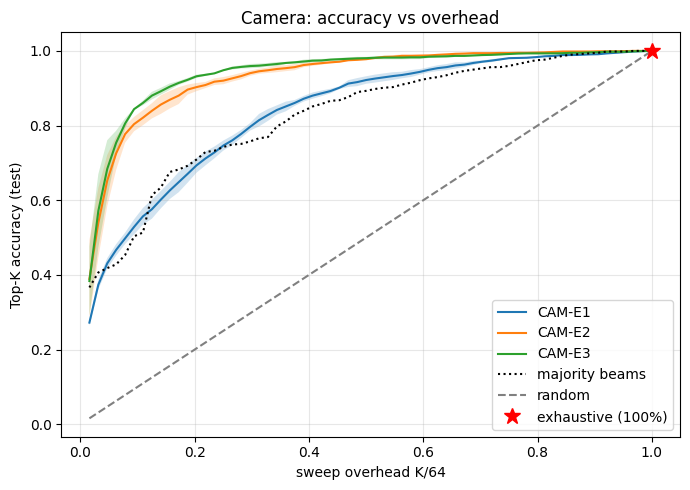

best camera model: CAM-E3 -> exported to /kaggle/working/camera_p1/results/CAM-BEST
zip: /kaggle/working/camera_p1_deliverables.zip (223 MB)


In [10]:
def baselines():
    fr = pd.Series(Y_NP[ROWS["train"]]).value_counts().index.tolist(); Yt_ = Y_NP[ROWS["test"]]
    return {"random": {k: k / 64 for k in KS}, "majority beam": {k: float(np.isin(Yt_, fr[:k]).mean()) for k in KS},
            "exhaustive sweep (64)": {k: 1.0 for k in KS}}

rows = []
for e in EXPERIMENTS:
    if not (RESULTS / e / "done.json").exists(): continue
    R = pd.DataFrame([json.load(open(RESULTS / e / f"seed{s}.json")) for s in runs(e)])
    ms = lambda c: f"{R[c].mean():.3f} ± {R[c].std(ddof=1):.3f}" if len(R) > 1 else f"{R[c].mean():.3f}"
    rows.append({"experiment": e, "model": EXPERIMENTS[e]["title"], "seeds": len(R),
                 "top1": ms("top1"), "top3": ms("top3"), "top5": ms("top5"),
                 "pwr_loss_dB@top1": f"{R.pwr_loss_db_top1.mean():.2f}", "pwr_loss_dB@top3": f"{R.pwr_loss_db_top3.mean():.2f}",
                 "pwr_loss_dB@top5": f"{R.pwr_loss_db_top5.mean():.2f}", "overhead@1/3/5": "1/64, 3/64, 5/64",
                 "params": f"{int(R.params.iloc[0]):,}", "train_min/run": f"{R.train_time_s.mean() / 60:.1f}",
                 "val_score": f"{R.val_score.mean():.3f}", "_vs": R.val_score.mean()})
for name, b in baselines().items():
    rows.append({"experiment": "baseline", "model": name, "seeds": "-", "top1": f"{b[1]:.3f}", "top3": f"{b[3]:.3f}", "top5": f"{b[5]:.3f}"})
T = pd.DataFrame(rows); Tp = T.drop(columns="_vs").fillna("")
Tp.to_csv(RESULTS / "camera_master_table.csv", index=False)
try: _md = Tp.to_markdown(index=False)
except Exception: _md = Tp.to_string(index=False)
(RESULTS / "camera_master_table.md").write_text(_md)
pd.set_option("display.width", 250, "display.max_columns", 30); display(Tp)

# Top-K accuracy vs sweep overhead, K = 1..64
Yt = torch.from_numpy(Y_NP[ROWS["test"]]).long()
fig, ax = plt.subplots(figsize=(7, 5)); K = np.arange(1, 65)
for e in EXPERIMENTS:
    if not (RESULTS / e / "done.json").exists(): continue
    cs = []
    for s in runs(e):
        L = torch.from_numpy(np.load(RESULTS / e / f"seed{s}_test_logits.npy"))
        rk = (L > L.gather(1, Yt[:, None])).sum(1).numpy(); cs.append([(rk < k).mean() for k in K])
    cs = np.array(cs); ax.plot(K / 64, cs.mean(0), label=e)
    ax.fill_between(K / 64, cs.mean(0) - cs.std(0), cs.mean(0) + cs.std(0), alpha=.2)
fr = pd.Series(Y_NP[ROWS["train"]]).value_counts().index.tolist()
ax.plot(K / 64, [np.isin(Y_NP[ROWS["test"]], fr[:k]).mean() for k in K], "k:", label="majority beams")
ax.plot(K / 64, K / 64, "gray", ls="--", label="random"); ax.plot([1], [1], "r*", ms=12, label="exhaustive (100%)")
ax.set_xlabel("sweep overhead K/64"); ax.set_ylabel("Top-K accuracy (test)"); ax.set_title("Camera: accuracy vs overhead")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.savefig(RESULTS / "camera_topk_vs_overhead.png", dpi=130); plt.show()

# best camera model by mean VAL score -> results/CAM-BEST (what fusion loads)
done = [r for r in rows if r["experiment"].startswith("CAM")]
if done:
    best = max(done, key=lambda r: r["_vs"])["experiment"]; dst = RESULTS / "CAM-BEST"
    shutil.rmtree(dst, ignore_errors=True); dst.mkdir()
    for f in (RESULTS / best).glob("seed*"): shutil.copy(f, dst / f.name)
    json.dump({"best_experiment": best, "selected_by": "mean val score (mean of top1/3/5) over seeds",
               "files": "seed{s}_{val,test,train}_logits.npy: rows in ascending master.csv row order within each split; "
                        "seed{s}_embeddings.npy: (N, D) float16 for ALL samples in master.csv row order; "
                        "seed{s}_{train,val,test}_embeddings.npy: same, sliced by split.",
               "split_file": str(SPLIT_FILE)}, open(dst / "BEST.json", "w"), indent=1)
    print("best camera model:", best, "-> exported to", dst)

zp = shutil.make_archive(str(BASE / "camera_p1_deliverables"), "zip", OUT)
print("zip:", zp, f"({os.path.getsize(zp) / 1e6:.0f} MB)")

In [11]:
"hi"

'hi'

# Phase 2

In [3]:
import inspect
import gdown
from pathlib import Path

FOLDER_ID = "1m_6KqQr4QVNpg3bj_Tn9IkFqKOc8MPbM"
DL = Path("/kaggle/working/drive_dl")

kw = dict(id=FOLDER_ID, output=str(DL), quiet=False, use_cookies=False)
if "remaining_ok" in inspect.signature(gdown.download_folder).parameters:
    kw["remaining_ok"] = True                        # lifts the 50-file cap on newer gdown
print("gdown", gdown.__version__)

if not any(DL.rglob("*.zip")):
    DL.mkdir(parents=True, exist_ok=True)
    gdown.download_folder(**kw)

files = sorted(p for p in DL.rglob("*") if p.is_file())
print(f"\n{len(files)} files, {sum(p.stat().st_size for p in files) / 1e6:.0f} MB")
for p in files:
    print(f"{p.stat().st_size / 1e6:8.1f} MB  {p.relative_to(DL)}")

gdown 5.2.2


Retrieving folder contents


Retrieving folder 1R4-lYW_vxMOMPMAKnxopea6LxvHKtoXj Camera
Processing file 1XQfpWA_mkLhVi1mxz5MzmXhTnGbx0f1c camera_p1_deliverables.zip
Retrieving folder 17auI2FzzFM6Im6FlWhO1XR4Y1oA725Fl GPS
Processing file 1j4IE_s1ZDLbLdLz7OvbJ-UxBqeJfCM3n gps_embeddings.zip
Processing file 1AKT66BA5eiuIFHrLegY97bugZgcB9j7I GPS.zip
Retrieving folder 1RFW64GiNraGei8w2iOOrbvJpmN80z40B LiDAR
Processing file 1c8pWFXYK2KlfT6qC7Vq5o36eHysmN6UY LID-E2_results_NEW.zip
Processing file 1Qn4OmS2Bv-eSnTBj76SCgECyjXFBpdVJ LID-E2_results.zip
Processing file 1PzP_pEXmuBBILFX8bGYIXthZI9oF_s6W LiDAR_all_results.zip
Retrieving folder 1UusvTor7uho2dvF-Mtt7vHFZRFmdfDnN RADAR
Processing file 1r3WFaQI6z3T9azsK9JW76mQUgR-ue9Jd RAD-E1_export.zip


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1XQfpWA_mkLhVi1mxz5MzmXhTnGbx0f1c
From (redirected): https://drive.google.com/uc?id=1XQfpWA_mkLhVi1mxz5MzmXhTnGbx0f1c&confirm=t&uuid=4fa54596-934b-4d6b-942f-b3f1a93d0648
To: /kaggle/working/drive_dl/Camera/camera_p1_deliverables.zip
100%|██████████| 223M/223M [00:03<00:00, 58.0MB/s] 
Downloading...
From: https://drive.google.com/uc?id=1j4IE_s1ZDLbLdLz7OvbJ-UxBqeJfCM3n
To: /kaggle/working/drive_dl/GPS/gps_embeddings.zip
100%|██████████| 3.35M/3.35M [00:00<00:00, 216MB/s]
Downloading...
From: https://drive.google.com/uc?id=1AKT66BA5eiuIFHrLegY97bugZgcB9j7I
To: /kaggle/working/drive_dl/GPS/GPS.zip
100%|██████████| 4.41M/4.41M [00:00<00:00, 37.9MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1c8pWFXYK2KlfT6qC7Vq5o36eHysmN6UY
From (redirected): https://drive.google.com/uc?id=1c8pWFXYK2KlfT6qC7Vq5o36eHysmN


7 files, 318 MB
   223.0 MB  Camera/camera_p1_deliverables.zip
     4.4 MB  GPS/GPS.zip
     3.3 MB  GPS/gps_embeddings.zip
    26.9 MB  LiDAR/LID-E2_results.zip
    26.9 MB  LiDAR/LID-E2_results_NEW.zip
    28.6 MB  LiDAR/LiDAR_all_results.zip
     4.5 MB  RADAR/RAD-E1_export.zip



Download completed


In [4]:
import os, re, zipfile
from pathlib import Path
from collections import defaultdict

DL      = Path("/kaggle/working/drive_dl")
EXTRACT = Path("/kaggle/working/unzipped"); EXTRACT.mkdir(parents=True, exist_ok=True)

# Unzip, including zips found inside zips. Same destination naming as Cell 1, so nothing is extracted twice.
done = set()
for _ in range(4):
    zips = [Path(d) / f for root in (DL, EXTRACT) for d, _, fs in os.walk(root) for f in fs if f.endswith(".zip")]
    new = [z for z in zips if z not in done]
    if not new:
        break
    for z in new:
        dst = EXTRACT / (z.parent.name + "__" + z.stem)
        if not dst.exists():
            try:
                with zipfile.ZipFile(z) as f:
                    f.extractall(dst)
                print("extracted:", z.relative_to(z.anchor))
            except zipfile.BadZipFile:
                print("BAD ZIP (partial download?):", z)
        done.add(z)

# Inventory: every folder that holds logits / embeddings / result jsons / master.csv / splits.json
PAT = re.compile(r"seed(\d+)_(val_logits|test_logits|embeddings)\.npy$|seed(\d+)\.json$")
inv, misc = defaultdict(lambda: defaultdict(list)), []
for root in (DL, EXTRACT):
    for d, _, fs in os.walk(root):
        for f in fs:
            m = PAT.match(f)
            if m:
                kind, seed = (m.group(2), m.group(1)) if m.group(2) else ("json", m.group(3))
                inv[Path(d)][kind].append(int(seed))
            elif f in ("master.csv", "splits.json", "stats.json", "power.npy"):
                misc.append(Path(d) / f)

print(f"\n{len(inv)} result folders:\n")
for d in sorted(inv):
    k = inv[d]
    print(d)
    print("    " + " | ".join(f"{n}: {sorted(k[n])}" for n in ("val_logits", "test_logits", "embeddings", "json") if k[n]))
print("\nother needed files:", *misc, sep="\n  ")

extracted: kaggle/working/drive_dl/Camera/camera_p1_deliverables.zip
extracted: kaggle/working/drive_dl/LiDAR/LID-E2_results_NEW.zip
extracted: kaggle/working/drive_dl/LiDAR/LiDAR_all_results.zip
extracted: kaggle/working/drive_dl/LiDAR/LID-E2_results.zip
extracted: kaggle/working/drive_dl/RADAR/RAD-E1_export.zip
extracted: kaggle/working/drive_dl/GPS/GPS.zip
extracted: kaggle/working/drive_dl/GPS/gps_embeddings.zip

13 result folders:

/kaggle/working/unzipped/Camera__camera_p1_deliverables/results/CAM-BEST
    val_logits: [0, 1, 2] | test_logits: [0, 1, 2] | embeddings: [0, 1, 2] | json: [0, 1, 2]
/kaggle/working/unzipped/Camera__camera_p1_deliverables/results/CAM-E1
    val_logits: [0, 1, 2] | test_logits: [0, 1, 2] | embeddings: [0, 1, 2] | json: [0, 1, 2]
/kaggle/working/unzipped/Camera__camera_p1_deliverables/results/CAM-E2
    val_logits: [0, 1, 2] | test_logits: [0, 1, 2] | embeddings: [0, 1, 2] | json: [0, 1, 2]
/kaggle/working/unzipped/Camera__camera_p1_deliverables/results/C

In [5]:
DIRS = {
    "GPS-E3": None,    # e.g. "/kaggle/working/unzipped/GPS__results/GPS-E3"
    "LID-E3": None,
    "CAM-E3": None,
    "RAD-E3": None,
}

def check_dirs():
    for exp, d in DIRS.items():
        if d is None:
            continue
        d = Path(d)
        have = sorted(p.name for p in d.glob("seed*_*_logits.npy")) if d.exists() else "FOLDER NOT FOUND"
        print(f"{exp}: {d}\n    {have}")
check_dirs()

In [6]:
import os, json, itertools, zipfile
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

INPUT   = Path("/kaggle/input")
EXTRACT = Path("/kaggle/working/unzipped"); EXTRACT.mkdir(parents=True, exist_ok=True)
OUT     = Path("/kaggle/working/late_fusion"); OUT.mkdir(parents=True, exist_ok=True)
DL      = Path("/kaggle/working/drive_dl")

def index_files(roots, skip_dirs=("scenario33",)):
    """One os.walk over the roots. Returns lists of zips, logits, master.csv and splits.json paths."""
    zips, logits, masters, splits = [], [], [], []
    for root in roots:
        for d, dirs, files in os.walk(root):
            dirs[:] = [x for x in dirs if x not in skip_dirs]     # don't crawl the raw sensor dump
            for f in files:
                p = Path(d) / f
                if f.endswith(".zip"):                    zips.append(p)
                elif f.endswith("_logits.npy"):           logits.append(p)
                elif f == "master.csv":                   masters.append(p)
                elif f == "splits.json":                  splits.append(p)
    return zips, logits, masters, splits


# unzip everything (nested zips too), then index input + extracted files together
done = set()
for _ in range(3):
    zips, *_ = index_files([INPUT, EXTRACT])
    new = [z for z in zips if z not in done]
    if not new:
        break
    for z in new:
        dst = EXTRACT / (z.parent.name + "__" + z.stem)
        if not dst.exists():
            with zipfile.ZipFile(z) as f:
                f.extractall(dst)
            print("extracted", z)
        done.add(z)

ZIPS, LOGITS, MASTERS, SPLITS = index_files([INPUT, EXTRACT])
print(f"\n{len(LOGITS)} logit files | master.csv: {[str(p) for p in MASTERS]} | splits.json: {[str(p) for p in SPLITS]}")


90 logit files | master.csv: [] | splits.json: ['/kaggle/working/unzipped/GPS__GPS/GPS/splits/splits.json', '/kaggle/working/unzipped/Camera__camera_p1_deliverables/splits/splits.json']


In [7]:
MODS = {                       # short name -> experiment id whose saved logits get fused
    "GPS": "GPS-E3",
    "LID": "LID-E3",
    "CAM": "CAM-E3",
    "RAD": "LID-E3",               # set to "RAD-E3" when M2 finishes
}
SEEDS     = (0, 1, 2)
MAX_SIZE  = 3                  # None -> all subsets once radar is in
CALIBRATE = True               # per-modality temperature fit on val
GRID_STEP = 0.05               # weight grid resolution on the simplex
N_BEAMS   = 64

In [8]:
RAW_ROOT = Path("/kaggle/input/datasets/haythemkrid/deepsense6g-scenario-33")   # raw dataset
CSV_NAME = "scenario33_dev.csv"

# ---- master: use a real master.csv if one was found, else rebuild the 3 needed columns from the raw CSV
cands = [p for p in MASTERS if {"idx", "seq", "beam0"} <= set(pd.read_csv(p, nrows=1).columns)]
if cands:
    master = pd.read_csv(cands[0]); print("master: loaded", cands[0], master.shape)
else:
    csv = next(iter([RAW_ROOT / CSV_NAME, RAW_ROOT / "scenario33" / CSV_NAME]
                    + list(RAW_ROOT.glob(f"*/{CSV_NAME}")) + list(RAW_ROOT.glob(CSV_NAME))), None)
    csv = next((p for p in [RAW_ROOT / CSV_NAME, RAW_ROOT / "scenario33" / CSV_NAME,
                            *RAW_ROOT.glob(f"*/{CSV_NAME}")] if p.exists()), None)
    assert csv is not None, f"{CSV_NAME} not found under {RAW_ROOT}. Check the path with: !ls {RAW_ROOT}"
    df = pd.read_csv(csv, index_col=0).sort_index()
    master = pd.DataFrame({"idx": df.index.values, "seq": df["seq_index"].values,
                           "beam0": df["unit1_beam"].values - 1})            # same as stage_meta
    print("master: rebuilt from", csv, master.shape)


# ---- split: use the committed splits.json if present, else regenerate (same algorithm/seed as common/splits.py)
def make_splits(m, seed=0, val_frac=0.15, test_frac=0.15, n_trials=5000):
    N = len(m)
    sizes = m.groupby("seq").size()
    beams_of = m.groupby("seq")["beam0"].apply(set).to_dict()
    cnt = {s: g.value_counts() for s, g in m.groupby("seq")["beam0"]}
    rng = np.random.default_rng(seed)
    best, best_score = None, 1e9
    for _ in range(n_trials):
        order = rng.permutation(sizes.index.values)
        te, va, tr, nt, nv = [], [], [], 0, 0
        for s in order:
            if nt < test_frac * N:   te.append(s); nt += sizes[s]
            elif nv < val_frac * N:  va.append(s); nv += sizes[s]
            else:                    tr.append(s)
        seen = set().union(*[beams_of[s] for s in tr])
        unseen = sum(c for s in te + va for b, c in cnt[s].items() if b not in seen) / (nt + nv)
        score = abs(nt / N - test_frac) + abs(nv / N - val_frac) + 2 * unseen
        if score < best_score:
            best_score, best = score, (tr, va, te)
    return {name: [int(i) for i in m[m.seq.isin(seqs)].idx]
            for name, seqs in zip(("train", "val", "test"), best)}


split_ok = [p for p in SPLITS if {"train", "val", "test"} <= set(json.load(open(p)))]
if split_ok:
    sp = json.load(open(split_ok[0])); print("split: loaded", split_ok[0])
else:
    sp = make_splits(master, seed=0); print("split: splits.json not found -> regenerated (seed 0)")


def labels(split):
    rows = master.index[master.idx.isin(set(sp[split]))].to_numpy()      # master order, like BeamDataset
    return master.beam0.to_numpy()[rows].astype(np.int64), master.seq.to_numpy()[rows]

yval, seqval   = labels("val")
ytest, seqtest = labels("test")
print(f"val rows {len(yval)} (seqs {sorted(set(seqval))}) | test rows {len(ytest)} (seqs {sorted(set(seqtest))})")

master: rebuilt from /kaggle/input/datasets/haythemkrid/deepsense6g-scenario-33/scenario33/scenario33_dev.csv (3981, 3)
split: loaded /kaggle/working/unzipped/GPS__GPS/GPS/splits/splits.json
val rows 602 (seqs [np.int64(10), np.int64(12), np.int64(16)]) | test rows 598 (seqs [np.int64(4), np.int64(8)])


In [9]:
def ranks_of_true(S, y):
    """1 = true beam ranked first. Ties count against the model (same as common.metrics)."""
    S = np.asarray(S); true = S[np.arange(len(y)), y][:, None]
    return (S > true).sum(1) + 1


def metrics(S, y):
    r = ranks_of_true(S, y)
    cdf = np.array([(r <= k).mean() for k in range(1, N_BEAMS + 1)])
    out = {f"top{k}": cdf[k - 1] for k in (1, 3, 5)}
    for t in (90, 95):
        ok = np.where(cdf >= t / 100)[0]
        K = int(ok[0] + 1) if len(ok) else N_BEAMS
        out[f"K{t}"] = K; out[f"gain_K{t}"] = 1 - K / N_BEAMS
    return out


def find(exp, seed, split):
    name = f"seed{seed}_{split}_logits.npy"
    if DIRS.get(exp):                                        # pinned folder wins
        p = Path(DIRS[exp]) / name
        return p if p.exists() else None
    hits = sorted(p for p in LOGITS if p.name == name and exp in p.parts)   # fallback: match folder name
    return hits[0] if hits else None


RAW = {}                                           # RAW[mod][seed] = {"val": (Nv,64), "test": (Nt,64)}
for mod, exp in MODS.items():
    if exp is None:
        continue
    RAW[mod] = {}
    for s in SEEDS:
        pv, pt = find(exp, s, "val"), find(exp, s, "test")
        if pv is None or pt is None:
            print(f"[missing] {mod} ({exp}) seed {s}: val={pv is not None} test={pt is not None}")
            continue
        v, t = np.load(pv).astype(np.float32), np.load(pt).astype(np.float32)
        assert v.shape == (len(yval), N_BEAMS),  f"{exp} seed{s} val {v.shape} vs labels {len(yval)}: split mismatch"
        assert t.shape == (len(ytest), N_BEAMS), f"{exp} seed{s} test {t.shape} vs labels {len(ytest)}: split mismatch"
        RAW[mod][s] = {"val": v, "test": t, "dir": pt.parent}
        print(f"[ok] {mod:3s} seed{s}: {pt}")

ACTIVE   = [m for m in MODS if m in RAW and RAW[m]]
SEEDS_OK = [s for s in SEEDS if all(s in RAW[m] for m in ACTIVE)]
assert ACTIVE and SEEDS_OK, "nothing loaded: check MODS ids against the extracted folder names printed in Cell 1"
print("\nactive:", ACTIVE, "| seeds:", SEEDS_OK)

# ---- sanity: recompute standalone metrics from logits, compare with teammates' own json when present
rows = []
for m in ACTIVE:
    for s in SEEDS_OK:
        r = metrics(RAW[m][s]["test"], ytest)
        j = RAW[m][s]["dir"] / f"seed{s}.json"
        ref = json.load(open(j)) if j.exists() else {}
        rows.append({"mod": m, "seed": s, "top1": r["top1"], "json_top1": ref.get("top1", np.nan),
                     "K90": r["K90"], "json_K90": ref.get("K90", np.nan)})
chk = pd.DataFrame(rows)
print(chk.round(3).to_string(index=False))
print("\nGPS-E3 reference: top1 .556, top3 .852, top5 .928, K90 5")

[ok] GPS seed0: /kaggle/working/unzipped/GPS__GPS/GPS/results/GPS-E3/seed0_test_logits.npy
[ok] GPS seed1: /kaggle/working/unzipped/GPS__GPS/GPS/results/GPS-E3/seed1_test_logits.npy
[ok] GPS seed2: /kaggle/working/unzipped/GPS__GPS/GPS/results/GPS-E3/seed2_test_logits.npy
[ok] LID seed0: /kaggle/working/unzipped/LiDAR__LiDAR_all_results/LID-E3/seed0_test_logits.npy
[ok] LID seed1: /kaggle/working/unzipped/LiDAR__LiDAR_all_results/LID-E3/seed1_test_logits.npy
[ok] LID seed2: /kaggle/working/unzipped/LiDAR__LiDAR_all_results/LID-E3/seed2_test_logits.npy
[ok] CAM seed0: /kaggle/working/unzipped/Camera__camera_p1_deliverables/results/CAM-E3/seed0_test_logits.npy
[ok] CAM seed1: /kaggle/working/unzipped/Camera__camera_p1_deliverables/results/CAM-E3/seed1_test_logits.npy
[ok] CAM seed2: /kaggle/working/unzipped/Camera__camera_p1_deliverables/results/CAM-E3/seed2_test_logits.npy
[ok] RAD seed0: /kaggle/working/unzipped/LiDAR__LiDAR_all_results/LID-E3/seed0_test_logits.npy
[ok] RAD seed1: /kag

In [10]:
def softmax(L, T=1.0):
    z = L / T; z = z - z.max(1, keepdims=True); e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def nll(P, y):
    return -np.log(P[np.arange(len(y)), y] + 1e-12).mean()

def fit_temperature(Lval, y):
    grid = np.exp(np.linspace(np.log(0.1), np.log(30), 80))
    return float(grid[np.argmin([nll(softmax(Lval, T), y) for T in grid])])

def simplex_grid(m, step):
    n = round(1 / step)
    pts = [c + (n - sum(c),) for c in itertools.product(range(n + 1), repeat=m - 1) if sum(c) <= n]
    return np.array(pts, dtype=np.float64) / n

def fit_weights(Pvals, y):
    """Minimise val NLL of sum_m w_m p_m over the simplex (only true-class probs needed)."""
    ptrue = np.stack([P[np.arange(len(y)), y] for P in Pvals])
    W = simplex_grid(len(Pvals), GRID_STEP)
    return W[np.argmin(-np.log(W @ ptrue + 1e-12).mean(1))]

PROB = {m: {} for m in ACTIVE}
for m in ACTIVE:
    for s in SEEDS_OK:
        T = fit_temperature(RAW[m][s]["val"], yval) if CALIBRATE else 1.0
        PROB[m][s] = {"val": softmax(RAW[m][s]["val"], T), "test": softmax(RAW[m][s]["test"], T), "T": T}
print("temperatures:", {m: [round(PROB[m][s]["T"], 2) for s in SEEDS_OK] for m in ACTIVE})

def fuse(subset, seed, method):
    Pv = [PROB[m][seed]["val"] for m in subset]; Pt = [PROB[m][seed]["test"] for m in subset]
    w = np.ones(len(subset)) / len(subset) if (method == "avg" or len(subset) == 1) else fit_weights(Pv, yval)
    return sum(wi * P for wi, P in zip(w, Pt)), w

temperatures: {'GPS': [1.35, 1.35, 1.35], 'LID': [3.2, 3.2, 2.77], 'CAM': [1.08, 1.16, 1.08], 'RAD': [3.2, 3.2, 2.77]}


In [11]:
max_size = len(ACTIVE) if MAX_SIZE is None else min(MAX_SIZE, len(ACTIVE))
subsets  = [c for k in range(1, max_size + 1) for c in itertools.combinations(ACTIVE, k)]
recs = []

for sub in subsets:
    for s in SEEDS_OK:
        for method in ("avg", "wavg"):
            scores, w = fuse(sub, s, method)
            recs.append({"subset": "+".join(sub), "size": len(sub), "method": method, "seed": s,
                         **metrics(scores, ytest), **{f"w_{m}": wi for m, wi in zip(sub, w)}})
res = pd.DataFrame(recs); res.to_csv(OUT / "late_fusion_per_seed.csv", index=False)

mcols = ["top1", "top3", "top5", "K90", "K95", "gain_K90", "gain_K95"]
wcols = [f"w_{m}" for m in ACTIVE]
g = res.groupby(["subset", "size", "method"])
mean = g[mcols + wcols].mean().reset_index()
std  = g[mcols].std(ddof=0).reset_index()

summary = mean[["subset", "size", "method"]].copy()
for c in mcols:
    summary[c] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(mean[c], std[c])]
summary["weights"] = [" ".join(f"{m}:{r[f'w_{m}']:.2f}" for m in ACTIVE if not np.isnan(r[f"w_{m}"]))
                      for _, r in mean.iterrows()]
order = mean.assign(_t=-mean.top1).sort_values(["K90", "K95", "_t"]).index
summary = summary.loc[order]; summary.to_csv(OUT / "late_fusion_summary.csv", index=False)

pd.set_option("display.width", 220, "display.max_colwidth", 60)
print("--- weighted (weights fit on val) ---")
print(summary[summary.method == "wavg"].to_string(index=False))
print("\n--- equal-weight average ---")
print(summary[summary.method == "avg"].to_string(index=False))

--- weighted (weights fit on val) ---
     subset  size method          top1          top3          top5            K90            K95      gain_K90      gain_K95                    weights
    GPS+CAM     2   wavg 0.538 ± 0.013 0.854 ± 0.005 0.930 ± 0.005  4.333 ± 0.471  6.667 ± 0.471 0.932 ± 0.007 0.896 ± 0.007          GPS:0.75 CAM:0.25
GPS+CAM+RAD     3   wavg 0.538 ± 0.013 0.854 ± 0.005 0.930 ± 0.005  4.333 ± 0.471  6.667 ± 0.471 0.932 ± 0.007 0.896 ± 0.007 GPS:0.75 CAM:0.25 RAD:0.00
GPS+LID+CAM     3   wavg 0.538 ± 0.013 0.854 ± 0.005 0.930 ± 0.005  4.333 ± 0.471  6.667 ± 0.471 0.932 ± 0.007 0.896 ± 0.007 GPS:0.75 LID:0.00 CAM:0.25
        GPS     1   wavg 0.556 ± 0.011 0.852 ± 0.003 0.928 ± 0.003  5.000 ± 0.000  6.667 ± 0.471 0.922 ± 0.000 0.896 ± 0.007                   GPS:1.00
    GPS+LID     2   wavg 0.555 ± 0.010 0.852 ± 0.003 0.927 ± 0.005  5.000 ± 0.000  6.667 ± 0.471 0.922 ± 0.000 0.896 ± 0.007          GPS:0.95 LID:0.05
GPS+LID+RAD     3   wavg 0.555 ± 0.010 0.852 ± 0.0

In [12]:
M = mean[mean.method == "wavg"].set_index("subset")
rows = []
for base in M.index:
    S = set(base.split("+"))
    for m in ACTIVE:
        if m in S:
            continue
        tgt = "+".join(x for x in ACTIVE if x in S | {m})
        if tgt in M.index:
            rows.append({"base": base, "add": m, "base_size": len(S),
                         "dTop1": M.top1[tgt] - M.top1[base], "dTop3": M.top3[tgt] - M.top3[base],
                         "dK90": M.K90[tgt] - M.K90[base],    "dK95": M.K95[tgt] - M.K95[base]})
marg = pd.DataFrame(rows); marg.to_csv(OUT / "marginal_contribution.csv", index=False)

print("dK90 < 0 means the added modality helps:")
print(marg.sort_values(["base", "dK90"]).round(3).to_string(index=False))
print("\nAverage by added modality and base size:")
print(marg.groupby(["add", "base_size"])[["dTop1", "dTop3", "dK90", "dK95"]].mean().round(3))

dK90 < 0 means the added modality helps:
   base add  base_size  dTop1  dTop3    dK90    dK95
    CAM GPS          1  0.154  0.170  -6.000 -10.667
    CAM LID          1  0.002  0.004  -0.333   0.333
    CAM RAD          1  0.002  0.004  -0.333   0.333
CAM+RAD GPS          2  0.152  0.166  -5.667 -11.000
CAM+RAD LID          2  0.000  0.000   0.000   0.000
    GPS CAM          1 -0.018  0.002  -0.667   0.000
    GPS LID          1 -0.001  0.000   0.000   0.000
    GPS RAD          1 -0.001  0.000   0.000   0.000
GPS+CAM LID          2  0.000  0.000   0.000   0.000
GPS+CAM RAD          2  0.000  0.000   0.000   0.000
GPS+LID CAM          2 -0.017  0.002  -0.667   0.000
GPS+LID RAD          2  0.000  0.000   0.000   0.000
GPS+RAD CAM          2 -0.017  0.002  -0.667   0.000
GPS+RAD LID          2  0.000  0.000   0.000   0.000
    LID GPS          1  0.201  0.412 -31.667 -39.000
    LID CAM          1  0.032  0.248 -26.667 -28.000
    LID RAD          1  0.000  0.000   0.000   0.000
LID+C

In [13]:
def hit_arrays(k):
    return {m: {s: ranks_of_true(RAW[m][s]["test"], ytest) <= k for s in SEEDS_OK} for m in ACTIVE}

def phi(a, b):
    return np.corrcoef(~a, ~b)[0, 1] if a.min() != a.max() and b.min() != b.max() else np.nan

def complementarity(k):
    H, out = hit_arrays(k), []
    for a, b in itertools.combinations(ACTIVE, 2):
        acc = [[(H[a][s] & ~H[b][s]).mean(), (~H[a][s] & H[b][s]).mean(), (H[a][s] & H[b][s]).mean(),
                (~H[a][s] & ~H[b][s]).mean(), (H[a][s] | H[b][s]).mean(),
                max(H[a][s].mean(), H[b][s].mean()), phi(H[a][s], H[b][s])] for s in SEEDS_OK]
        v = np.nanmean(acc, 0)
        out.append({"pair": f"{a}+{b}", "only_first": v[0], "only_second": v[1], "both": v[2], "none": v[3],
                    "oracle": v[4], "best_single": v[5], "oracle_gain": v[4] - v[5], "err_corr": v[6]})
    return pd.DataFrame(out).set_index("pair")

for k in (1, 3):
    print(f"\nTop-{k}: oracle_gain = ceiling gain from fusing; err_corr near 1 = same mistakes")
    comp = complementarity(k).round(3); comp.to_csv(OUT / f"complementarity_top{k}.csv"); print(comp.to_string())


Top-1: oracle_gain = ceiling gain from fusing; err_corr near 1 = same mistakes
         only_first  only_second   both   none  oracle  best_single  oracle_gain  err_corr
pair                                                                                      
GPS+LID       0.223        0.021  0.333  0.423   0.577        0.556        0.021     0.574
GPS+CAM       0.236        0.063  0.321  0.381   0.619        0.556        0.063     0.442
GPS+RAD       0.223        0.021  0.333  0.423   0.577        0.556        0.021     0.574
LID+CAM       0.105        0.134  0.249  0.512   0.488        0.411        0.077     0.471
LID+RAD       0.000        0.000  0.354  0.646   0.354        0.354        0.000     1.000
CAM+RAD       0.134        0.105  0.249  0.512   0.488        0.411        0.077     0.471

Top-3: oracle_gain = ceiling gain from fusing; err_corr near 1 = same mistakes
         only_first  only_second   both   none  oracle  best_single  oracle_gain  err_corr
pair                 

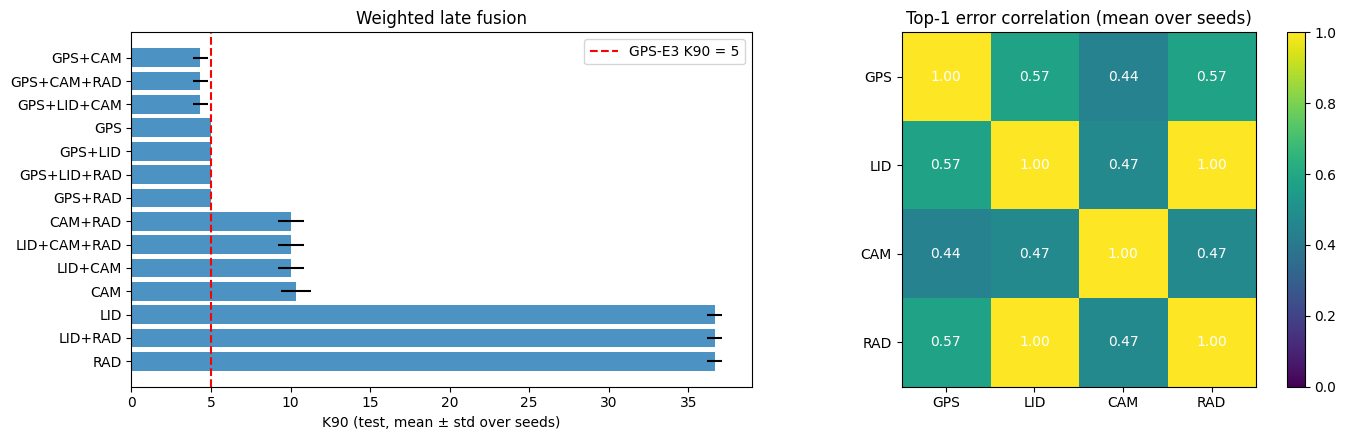

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

W  = mean[mean.method == "wavg"].merge(std, on=["subset", "size", "method"], suffixes=("", "_sd")).sort_values("K90")
ax[0].barh(W.subset, W.K90, xerr=W.K90_sd, color="tab:blue", alpha=.8)
ax[0].axvline(5, color="r", ls="--", label="GPS-E3 K90 = 5")
ax[0].invert_yaxis(); ax[0].legend(); ax[0].set_xlabel("K90 (test, mean ± std over seeds)")
ax[0].set_title("Weighted late fusion")

H1 = hit_arrays(1)
err = np.array([[np.nanmean([phi(H1[a][s], H1[b][s]) for s in SEEDS_OK]) for b in ACTIVE] for a in ACTIVE])
im = ax[1].imshow(err, vmin=0, vmax=1, cmap="viridis")
ax[1].set_xticks(range(len(ACTIVE))); ax[1].set_xticklabels(ACTIVE)
ax[1].set_yticks(range(len(ACTIVE))); ax[1].set_yticklabels(ACTIVE)
for i in range(len(ACTIVE)):
    for j in range(len(ACTIVE)):
        ax[1].text(j, i, f"{err[i, j]:.2f}", ha="center", va="center", color="w")
ax[1].set_title("Top-1 error correlation (mean over seeds)"); plt.colorbar(im, ax=ax[1])

plt.tight_layout(); plt.savefig(OUT / "late_fusion.png", dpi=150); plt.show()

# Final Phase

In [19]:
import pickle
from collections import defaultdict
import torch, torch.nn as nn, torchvision
from PIL import Image
from tqdm.auto import tqdm
dev = "cuda" if torch.cuda.is_available() else "cpu"

S31_ROOT = Path("/kaggle/input/datasets/haythemkrid/deepsense6g-scenario-31/scenario31_new/scenario31")        # <- edit

def first_csv(root, need="unit1_beam"):
    for p in [*root.glob("*.csv"), *root.glob("*/*.csv")]:
        if need in pd.read_csv(p, nrows=1, index_col=0).columns:
            return p

CSV33 = next(p for p in [RAW_ROOT / CSV_NAME, RAW_ROOT / "scenario33" / CSV_NAME] if p.exists())
CSV31 = first_csv(S31_ROOT)
assert CSV31 is not None, "no csv with unit1_beam under S31_ROOT"
print("33:", CSV33, "\n31:", CSV31)

def load_scn(csv):
    df = pd.read_csv(csv, index_col=0).sort_index()
    seq = df["seq_index"].to_numpy() if "seq_index" in df else np.zeros(len(df), int)
    has = {"cam": "unit1_rgb" in df, "rad": "unit1_radar" in df,
           "gps": {"unit1_loc", "unit2_loc"} <= set(df.columns)}
    y = df["unit1_beam"].to_numpy().astype(int) - 1                      # same 1..64 -> 0..63 convention as 33
    assert 0 <= y.min() and y.max() < N_BEAMS, f"beam range {y.min()}..{y.max()}: check convention"
    pos = pd.Series(seq).groupby(seq).cumcount().to_numpy()
    return dict(df=df, root=csv.parent, has=has, seq=seq, pos=pos, y=y)

D = {"33": load_scn(CSV33), "31": load_scn(CSV31)}
assert np.array_equal(D["33"]["df"].index.to_numpy(), master.idx.to_numpy()), "33 row order != master"
for k, d in D.items():
    print(f"\nscenario {k}: rows {len(d['y'])} | seqs {len(np.unique(d['seq']))} | has {d['has']}")
    print("  columns:", list(d["df"].columns))
    print("  beam range:", d["y"].min(), "-", d["y"].max(), "| top beams:", np.bincount(d["y"], minlength=64).argsort()[::-1][:5])

33: /kaggle/input/datasets/haythemkrid/deepsense6g-scenario-33/scenario33/scenario33_dev.csv 
31: /kaggle/input/datasets/haythemkrid/deepsense6g-scenario-31/scenario31_new/scenario31/scenario31_dev.csv

scenario 33: rows 3981 | seqs 18 | has {'cam': True, 'rad': True, 'gps': True}
  columns: ['unit1_rgb', 'unit1_pwr_60ghz', 'unit1_lidar', 'unit1_radar', 'unit1_loc', 'unit2_loc', 'unit1_beam', 'unit1_max_pwr', 'time_stamp', 'seq_index', 'unit2_spd_over_grnd_kmph', 'unit2_num_sats', 'unit2_altitude', 'unit2_geo_sep', 'unit2_mode_fix_type', 'unit2_pdop', 'unit2_hdop', 'unit2_vdop', 'unit2_interpolated_position']
  beam range: 1 - 63 | top beams: [21 19 15 20 12]

scenario 31: rows 7012 | seqs 52 | has {'cam': True, 'rad': True, 'gps': True}
  columns: ['unit1_rgb', 'unit1_pwr_60ghz', 'unit1_lidar', 'unit1_radar', 'unit1_loc', 'unit2_loc', 'unit1_beam', 'unit1_max_pwr', 'time_stamp', 'seq_index', 'unit2_spd_over_grnd_kmph', 'unit2_num_sats', 'unit2_altitude', 'unit2_geo_sep', 'unit2_mode_f

In [20]:
R33 = {s: master.index[master.idx.isin(set(sp[s]))].to_numpy() for s in ("train", "val", "test")}
HIST = 3                                                  # GPS and box history length

def gps_feats(d):
    df, root = d["df"], d["root"]
    lat0, lon0 = np.loadtxt(root / df["unit1_loc"].iloc[0])
    g = np.array([np.loadtxt(root / p) for p in df["unit2_loc"]]); R = 6371000
    x = np.deg2rad(g[:, 1] - lon0) * R * np.cos(np.deg2rad(lat0)); y = np.deg2rad(g[:, 0] - lat0) * R
    b = np.arctan2(x, y)
    return np.c_[x, y, np.hypot(x, y), np.sin(b), np.cos(b)].astype(np.float32)

def hist(F, d, K=HIST):                                   # K previous frames, clamped at sequence start
    i = np.arange(len(F))
    return np.concatenate([F[np.maximum(i - k, i - d["pos"])] for k in range(K, -1, -1)], 1)

def cache(name, fn):
    f = OUT / f"cache_{name}.npy"
    if not f.exists():
        np.save(f, fn())
    return np.load(f)

def build_cam(d):
    a = np.zeros((len(d["df"]), 224, 400, 3), np.uint8)
    for i, p in enumerate(tqdm(d["df"]["unit1_rgb"], desc="cam")):
        a[i] = np.asarray(Image.open(d["root"] / p).convert("RGB").resize((400, 224), Image.BILINEAR))
    return a

def build_rad(d):                                          # range-angle map, same as build_cache.radar_ra
    a = np.zeros((len(d["df"]), 1, 256, 64), np.float16)
    for i, p in enumerate(tqdm(d["df"]["unit1_radar"], desc="rad")):
        f = np.fft.fft(np.load(d["root"] / p), axis=1)
        ra = np.fft.fftshift(np.abs(np.fft.fft(f, n=64, axis=0)).mean(axis=2), axes=0).T
        a[i, 0] = 20 * np.log10(ra + 1e-6)
    return a

for k, d in D.items():
    if d["has"]["cam"]: d["cam"] = cache(f"{k}_cam", lambda: build_cam(d))
    if d["has"]["rad"]: d["rad"] = cache(f"{k}_rad", lambda: build_rad(d))
    if d["has"]["gps"]: d["gps_raw"] = gps_feats(d)

# normalisation statistics from 33 TRAIN rows only, applied to both scenarios
tr = R33["train"]
GM, GS = D["33"]["gps_raw"][tr, :3].mean(0), D["33"]["gps_raw"][tr, :3].std(0)
RM, RS = float(D["33"]["rad"][tr[::5]].astype(np.float32).mean()), float(D["33"]["rad"][tr[::5]].astype(np.float32).std())
for k, d in D.items():
    if d["has"]["gps"]:
        F = d["gps_raw"].copy(); F[:, :3] = (F[:, :3] - GM) / GS
        d["gps_h"] = hist(F, d)
        print(f"{k} GPS x,y,dist (m): mean {d['gps_raw'][:, :3].mean(0).round(1)}, range of dist "
              f"{d['gps_raw'][:, 2].min():.0f}-{d['gps_raw'][:, 2].max():.0f}")

cam:   0%|          | 0/3981 [00:00<?, ?it/s]

rad:   0%|          | 0/3981 [00:00<?, ?it/s]

cam:   0%|          | 0/7012 [00:00<?, ?it/s]

rad:   0%|          | 0/7012 [00:00<?, ?it/s]

33 GPS x,y,dist (m): mean [10.3 33.  35.8], range of dist 10-52
31 GPS x,y,dist (m): mean [ 17.3 -29.9  35.7], range of dist 11-85


In [21]:
IMN_M = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
IMN_S = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

def make_x(mod, scn, idx, train=False):
    d = D[scn]
    if mod in ("gps", "box"):
        return torch.from_numpy(d[f"{mod}_h"][idx]).to(dev)
    if mod == "rad":
        return (torch.from_numpy(d["rad"][idx]).to(dev).float() - RM) / RS
    x = torch.from_numpy(d["cam"][idx]).to(dev).permute(0, 3, 1, 2).float() / 255
    if train:                                              # strong photometric aug: helps night -> day, NO flip
        n = len(x)
        b = torch.empty(n, 1, 1, 1, device=dev).uniform_(0.4, 1.8)
        c = torch.empty(n, 1, 1, 1, device=dev).uniform_(0.6, 1.4)
        x = ((x * b - 0.5) * c + 0.5).clamp(0, 1) ** torch.empty(n, 1, 1, 1, device=dev).uniform_(0.7, 1.4)
    return (x - IMN_M) / IMN_S

def mlp(i):   return nn.Sequential(nn.Linear(i, 128), nn.ReLU(), nn.Dropout(0.1),
                                   nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, N_BEAMS))

def mk_rad():                                              # <- swap for RAD-E1's real architecture
    blk = lambda i, o: [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(*blk(1, 32), *blk(32, 64), *blk(64, 128), *blk(128, 128),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, N_BEAMS))

def mk_cam():                                              # CAM-E2 setup: ResNet50 fine-tune
    m = torchvision.models.resnet50(weights="IMAGENET1K_V2")
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(2048, N_BEAMS)); return m

SPEC = {  # mod: (model factory, epochs, lr, batch)
    "GPS": ("gps", lambda: mlp(D["33"]["gps_h"].shape[1]), 100, 1e-3, 128),
    "RAD": ("rad", mk_rad, 30, 1e-3, 32),
    "CAM": ("cam", mk_cam, 12, 3e-4, 32),
}

@torch.no_grad()
def predict(net, mod, scn, idx):
    net.eval(); out = []
    for i in range(0, len(idx), 128):
        with torch.autocast(dev, enabled=dev == "cuda"):
            out.append(net(make_x(mod, scn, idx[i:i + 128])).float().cpu())
    return torch.cat(out).numpy()

def train_model(mod, factory, seed, epochs, lr, bs):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    net = factory().to(dev); y = D["33"]["y"]
    opt = torch.optim.AdamW(net.parameters(), lr, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * int(np.ceil(len(R33["train"]) / bs)))
    scaler = torch.amp.GradScaler(enabled=dev == "cuda")
    best, state = 1e9, None
    for ep in range(epochs):
        net.train(); perm = rng.permutation(R33["train"])
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            if len(b) < 2: continue
            with torch.autocast(dev, enabled=dev == "cuda"):
                loss = nn.functional.cross_entropy(net(make_x(mod, "33", b, True)).float(), torch.from_numpy(y[b]).to(dev))
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        v = nll(softmax(predict(net, mod, "33", R33["val"])), y[R33["val"]])
        if v < best:
            best, state = v, {k: t.clone() for k, t in net.state_dict().items()}
    net.load_state_dict(state)
    out = {"val": predict(net, mod, "33", R33["val"]), "test": predict(net, mod, "33", R33["test"])}
    if D["31"]["has"][{"gps": "gps", "rad": "rad", "cam": "cam", "box": "cam"}[mod]]:
        out["s31"] = predict(net, mod, "31", np.arange(len(D["31"]["y"])))
    return out

LG = defaultdict(dict)                                     # LG[mod][seed] = {"val","test","s31"}
def run(name, key, factory, epochs, lr, bs):
    for s in SEEDS:
        f = OUT / f"lg_{name}_seed{s}.npz"
        if f.exists():
            LG[name][s] = dict(np.load(f)); continue
        LG[name][s] = train_model(key, factory, s, epochs, lr, bs)
        np.savez_compressed(f, **LG[name][s]); print(f"trained {name} seed {s}")

for name, (key, factory, ep, lr, bs) in SPEC.items():
    if D["33"]["has"][{"gps": "gps", "rad": "rad", "cam": "cam"}[key]]:
        run(name, key, factory, ep, lr, bs)

trained GPS seed 0
trained GPS seed 1
trained GPS seed 2
trained RAD seed 0
trained RAD seed 1
trained RAD seed 2
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 217MB/s]


trained CAM seed 0
trained CAM seed 1
trained CAM seed 2


In [22]:
!pip -q install ultralytics

In [23]:
from ultralytics import YOLO
yolo = YOLO("yolov8s.pt")                                  # COCO-pretrained, zero-shot
VEH = [2, 5, 7]                                            # car, bus, truck

def track_scn(k):
    d, out = D[k], []
    paths = [d["root"] / p for p in d["df"]["unit1_rgb"]]
    for i, p in enumerate(tqdm(paths, desc=f"track {k}")):
        if d["pos"][i] == 0:
            yolo.predictor = None                          # resets the tracker at every sequence start
        b = yolo.track(str(p), persist=True, tracker="bytetrack.yaml", classes=VEH,
                       conf=0.15, imgsz=640, verbose=False)[0].boxes
        out.append(np.c_[b.id.cpu().numpy(), b.xyxyn.cpu().numpy(), b.conf.cpu().numpy()]
                   if len(b) and b.id is not None else np.zeros((0, 6), np.float32))
    return out

def target_feats(k, tracks):
    """Per sequence: the track with the largest accumulated area x conf is 'the target car'.
    Features per frame: present, cx, cy, w, h, conf, dcx, dcy (carried up to 3 frames when lost)."""
    d = D[k]; B = np.zeros((len(tracks), 8), np.float32)
    for s in np.unique(d["seq"]):
        rows = np.where(d["seq"] == s)[0]; score = defaultdict(float)
        for i in rows:
            for t, x1, y1, x2, y2, c in tracks[i]:
                score[t] += (x2 - x1) * (y2 - y1) * c
        if not score: continue
        tid, last = max(score, key=score.get), None
        for i in rows:
            hit = [t for t in tracks[i] if t[0] == tid]
            if hit:
                _, x1, y1, x2, y2, c = hit[0]
                B[i, :6] = [1, (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1, c]; last = i
            elif last is not None and i - last <= 3:
                B[i, :6] = B[last, :6]; B[i, 0] = 0.5
            if i > rows[0] and B[i, 0] == 1 and B[i - 1, 0] > 0:
                B[i, 6:8] = B[i, 1:3] - B[i - 1, 1:3]
    return B

f = OUT / "tracks.pkl"
if f.exists():
    TR = pickle.load(open(f, "rb"))
else:
    TR = {k: track_scn(k) for k in D if D[k]["has"]["cam"]}; pickle.dump(TR, open(f, "wb"))
for k, tracks in TR.items():
    B = target_feats(k, tracks); D[k]["box_h"] = hist(B, D[k])
    print(f"scenario {k}: target present in {(B[:, 0] == 1).mean():.1%} of frames, carried {(B[:, 0] == .5).mean():.1%}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


track 33:   0%|          | 0/3981 [00:00<?, ?it/s]

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 276ms
Prepared 1 package in 73ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



track 31:   0%|          | 0/7012 [00:00<?, ?it/s]

scenario 33: target present in 49.5% of frames, carried 3.1%
scenario 31: target present in 89.3% of frames, carried 0.8%


In [24]:
run("BOX", "box", lambda: mlp(D["33"]["box_h"].shape[1]), 100, 1e-3, 128)

yv = D["33"]["y"][R33["val"]]
def val_score(name):
    r = [metrics(LG[name][s]["val"], yv) for s in SEEDS]
    return np.mean([x["K90"] for x in r]), np.mean([x["top1"] for x in r])

kc, tc = val_score("CAM"); kb, tb = val_score("BOX")
print(f"val (33)  CAM : K90 {kc:.2f}  top1 {tc:.3f}\n          BOX : K90 {kb:.2f}  top1 {tb:.3f}")
ref = [find("CAM-E2", s, "val") for s in SEEDS]            # teammates' original CAM-E2, if their files are present
if all(p is not None for p in ref):
    r = [metrics(np.load(p), yv) for p in ref]
    print(f"          CAM-E2 (teammates): K90 {np.mean([x['K90'] for x in r]):.2f}  top1 {np.mean([x['top1'] for x in r]):.3f}")
ADOPT = (kb < kc) or (kb == kc and tb > tc)
print("\nBOX adopted into late fusion:", ADOPT)

trained BOX seed 0
trained BOX seed 1
trained BOX seed 2
val (33)  CAM : K90 27.33  top1 0.241
          BOX : K90 29.00  top1 0.107
          CAM-E2 (teammates): K90 29.00  top1 0.235

BOX adopted into late fusion: False


In [25]:
FM = [m for m in ("GPS", "RAD", "CAM") + (("BOX",) if ADOPT else ()) if m in LG]
PR = {m: {} for m in FM}
for m in FM:
    for s in SEEDS:
        T = fit_temperature(LG[m][s]["val"], yv)           # calibration fit on 33 val only
        PR[m][s] = {k: softmax(v, T) for k, v in LG[m][s].items()}

def fuse_xs(sub, s, method, split):
    w = (np.ones(len(sub)) / len(sub) if method == "avg" or len(sub) == 1
         else fit_weights([PR[m][s]["val"] for m in sub], yv))          # weights fit on 33 val only
    return sum(wi * PR[m][s][split] for wi, m in zip(w, sub)), w

y31 = D["31"]["y"]; ytest33 = D["33"]["y"][R33["test"]]
recs = []
for k in range(1, len(FM) + 1):
    for sub in itertools.combinations(FM, k):
        for method in ("avg", "wavg"):
            for s in SEEDS:
                for dom, split, yy in (("33 test", "test", ytest33), ("31 all", "s31", y31)):
                    if not all(split in PR[m][s] for m in sub): continue
                    S, w = fuse_xs(sub, s, method, split)
                    recs.append({"subset": "+".join(sub), "method": method, "domain": dom, "seed": s,
                                 **{c: v for c, v in metrics(S, yy).items() if c in ("top1", "top3", "top5", "K90", "K95")}})
# majority-beam prior as the floor
pri = np.bincount(D["33"]["y"][R33["train"]], minlength=N_BEAMS).astype(float)
for dom, yy in (("33 test", ytest33), ("31 all", y31)):
    recs.append({"subset": "prior(33 train)", "method": "-", "domain": dom, "seed": 0,
                 **{c: v for c, v in metrics(np.tile(pri, (len(yy), 1)), yy).items() if c in ("top1", "top3", "top5", "K90", "K95")}})

xs = pd.DataFrame(recs); xs.to_csv(OUT / "cross_scenario_fusion.csv", index=False)
cols = ["top1", "top3", "top5", "K90", "K95"]
mu = xs.groupby(["domain", "subset", "method"])[cols].mean()
sd = xs.groupby(["domain", "subset", "method"])[cols].std(ddof=0)
tab = pd.DataFrame({c: [f"{a:.3f} ± {b:.3f}" for a, b in zip(mu[c], sd[c])] for c in cols}, index=mu.index)
pd.set_option("display.width", 220, "display.max_rows", 500)
for dom in ("33 test", "31 all"):
    t = tab.loc[dom].assign(_k=mu.loc[dom, "K90"], _t=-mu.loc[dom, "top1"]).sort_values(["_k", "_t"]).drop(columns=["_k", "_t"])
    print(f"\n=== trained on 33, evaluated on {dom} ===\n", t.to_string())


=== trained on 33, evaluated on 33 test ===
                                  top1           top3           top5             K90             K95
subset          method                                                                             
GPS+RAD+CAM     wavg    0.537 ± 0.008  0.835 ± 0.011  0.907 ± 0.013   5.333 ± 0.471   9.667 ± 0.471
GPS             avg     0.537 ± 0.011  0.834 ± 0.010  0.904 ± 0.012   5.333 ± 0.471  10.000 ± 0.816
                wavg    0.537 ± 0.011  0.834 ± 0.010  0.904 ± 0.012   5.333 ± 0.471  10.000 ± 0.816
GPS+RAD         wavg    0.536 ± 0.011  0.834 ± 0.011  0.904 ± 0.013   5.333 ± 0.471  10.000 ± 0.816
GPS+CAM         wavg    0.535 ± 0.006  0.834 ± 0.010  0.909 ± 0.014   5.333 ± 0.471   9.333 ± 0.943
GPS+RAD+CAM     avg     0.527 ± 0.013  0.826 ± 0.018  0.902 ± 0.007   5.333 ± 0.471  11.667 ± 1.247
GPS+CAM         avg     0.525 ± 0.013  0.824 ± 0.017  0.903 ± 0.010   5.333 ± 0.471   9.667 ± 0.471
GPS+RAD         avg     0.542 ± 0.009  0.827 ± 0.007  

In [26]:
WDIR = OUT / "weights"; WDIR.mkdir(exist_ok=True)

In [29]:
ALL = [m for m in ("GPS", "RAD", "CAM", "BOX") if m in LG and all(s in LG[m] for s in SEEDS)]
PRX = {m: {} for m in ALL}
for m in ALL:
    for s in SEEDS:
        T = fit_temperature(LG[m][s]["val"], yv)                       # 33 val only
        PRX[m][s] = {k: softmax(v, T) for k, v in LG[m][s].items()}

def fuse_x(sub, s, method, split):
    w = (np.ones(len(sub)) / len(sub) if method == "avg" or len(sub) == 1
         else fit_weights([PRX[m][s]["val"] for m in sub], yv))
    return sum(wi * PRX[m][s][split] for wi, m in zip(w, sub)), w

recs = []
for k in range(1, len(ALL) + 1):
    for sub in itertools.combinations(ALL, k):
        for method in ("avg", "wavg"):
            for s in SEEDS:
                for dom, split, yy in (("33 test", "test", ytest33), ("31 all", "s31", y31)):
                    if not all(split in PRX[m][s] for m in sub): continue
                    S, _ = fuse_x(sub, s, method, split)
                    r = metrics(S, yy)
                    recs.append({"subset": "+".join(sub), "method": method, "domain": dom, "seed": s,
                                 **{c: r[c] for c in ("top1", "top3", "top5", "K90", "K95")}})
fx = pd.DataFrame(recs); fx.to_csv(OUT / "fusion_all4_33_to_31.csv", index=False)

cols = ["top1", "top3", "top5", "K90", "K95"]
mu = fx.groupby(["domain", "subset", "method"])[cols].mean()
for dom in ("33 test", "31 all"):
    t = mu.loc[dom].round(3).sort_values(["K90", "top1"], ascending=[True, False])
    print(f"\n=== trained on 33, evaluated on {dom} (wavg + avg, mean over seeds) ===")
    print(t[t.index.get_level_values("subset").str.contains("BOX")].to_string())

# BOX vs CAM head to head on 31, per seed
for m in ("CAM", "BOX"):
    if m in ALL:
        print(m, "31:", [(round(metrics(LG[m][s]["s31"], y31)["top1"], 3), metrics(LG[m][s]["s31"], y31)["K90"]) for s in SEEDS])


=== trained on 33, evaluated on 33 test (wavg + avg, mean over seeds) ===
                         top1   top3   top5     K90     K95
subset          method                                     
GPS+RAD+CAM+BOX wavg    0.537  0.835  0.907   5.333   9.667
GPS+RAD+BOX     wavg    0.536  0.834  0.904   5.333  10.000
GPS+BOX         wavg    0.535  0.834  0.904   5.333   9.667
GPS+CAM+BOX     wavg    0.535  0.834  0.909   5.333   9.333
                avg     0.524  0.814  0.896   6.000  12.000
GPS+RAD+CAM+BOX avg     0.524  0.805  0.892   6.333  14.667
GPS+BOX         avg     0.529  0.780  0.886   7.000  12.667
GPS+RAD+BOX     avg     0.522  0.766  0.864   9.000  15.333
CAM+BOX         wavg    0.467  0.716  0.790  12.333  20.667
RAD+CAM+BOX     wavg    0.467  0.716  0.790  12.333  20.667
CAM+BOX         avg     0.462  0.678  0.746  15.667  21.667
RAD+CAM+BOX     avg     0.460  0.654  0.731  16.667  24.333
RAD+BOX         avg     0.246  0.394  0.468  34.000  44.000
                wavg    0

                       top1                  K90                
p                       0.0    0.5    1.0    0.0     0.5     1.0
mode    weights fail                                            
corrupt clean   BOX   0.537  0.537  0.537  5.333   5.333   5.333
                CAM   0.537  0.535  0.533  5.333   5.333   5.667
                GPS   0.537  0.373  0.196  5.333  20.222  25.333
                RAD   0.537  0.538  0.537  5.333   5.333   5.333
        robust  BOX   0.534  0.534  0.535  5.333   5.333   5.333
                CAM   0.534  0.506  0.473  5.333   5.556   6.333
                GPS   0.534  0.431  0.328  5.333  13.000  17.667
                RAD   0.534  0.534  0.534  5.333   5.333   5.333
missing clean   BOX   0.537  0.537  0.537  5.333   5.333   5.333
                CAM   0.537  0.538  0.536  5.333   5.333   5.333
                GPS   0.537  0.504  0.467  5.333   9.111  14.667
                RAD   0.537  0.537  0.537  5.333   5.333   5.333
        robust  BOX   0.5

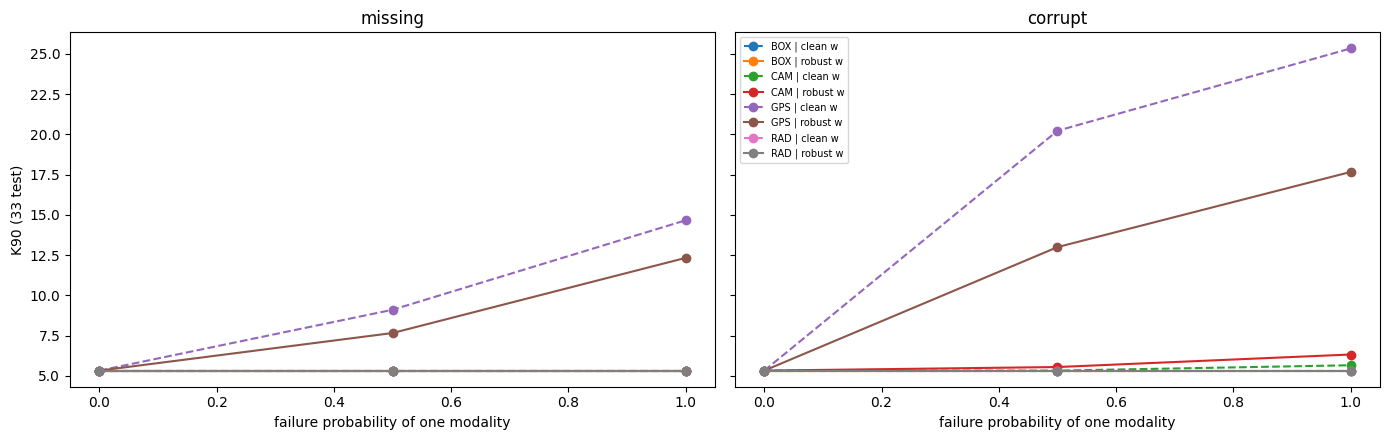

In [31]:
rng = np.random.default_rng(0)
LEVELS, REPS, MODES = (0.0, 0.5, 1.0), 3, ("missing", "corrupt")

def damage(P, mode, p):
    """missing: uniform output (sensor outage). corrupt: another sample's prediction (confidently wrong)."""
    bad = rng.random(len(P)) < p
    Q = P.copy()
    Q[bad] = 1.0 / N_BEAMS if mode == "missing" else P[rng.permutation(len(P))[bad]]
    return Q

def robust_w(sub, s, mode, p=0.3, R=5):
    Pv = [np.concatenate([damage(PRX[m][s]["val"], mode, p) for _ in range(R)]) for m in sub]
    return fit_weights(Pv, np.tile(yv, R))

full = tuple(ALL)
targets = [full] + [tuple(x for x in full if x != d) for d in full]          # all-N and every drop-one
recs = []
for sub in targets:
    for s in SEEDS:
        clean = fit_weights([PRX[m][s]["val"] for m in sub], yv)
        for mode in MODES:
            for wname, w in (("clean", clean), ("robust", robust_w(sub, s, mode))):
                for f in sub:
                    for p in LEVELS:
                        for _ in range(REPS if 0 < p < 1 else 1):
                            Pt = [damage(PRX[m][s]["test"], mode, p) if m == f else PRX[m][s]["test"] for m in sub]
                            r = metrics(sum(wi * P for wi, P in zip(w, Pt)), ytest33)
                            recs.append({"subset": "+".join(sub), "mode": mode, "weights": wname, "fail": f,
                                         "p": p, "seed": s, "top1": r["top1"], "K90": r["K90"], "K95": r["K95"]})
rob = pd.DataFrame(recs); rob.to_csv(OUT / "robustness_all.csv", index=False)

pd.set_option("display.max_rows", 500, "display.width", 200)
tab = rob[rob.subset == "+".join(full)].groupby(["mode", "weights", "fail", "p"])[["top1", "K90"]].mean().round(3)
print(tab.unstack("p").to_string())

# drop-one with refit weights (informed) vs sensor dies with clean weights (uninformed), p=1
print("\nK90 when one sensor is lost: refit without it  vs  clean weights, sensor outputs uniform")
for d in full:
    sub = tuple(x for x in full if x != d)
    a = rob[(rob.subset == "+".join(sub)) & (rob.p == 0)].K90.mean()
    b = rob[(rob.subset == "+".join(full)) & (rob["mode"] == "missing") & (rob.weights == "clean")
            & (rob.fail == d) & (rob.p == 1)].K90.mean()
    print(f"  lose {d}: refit {a:.2f} | uninformed {b:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for a_, mode in zip(ax, MODES):
    d = rob[(rob.subset == "+".join(full)) & (rob["mode"] == mode)]
    for (f, wn), g_ in d.groupby(["fail", "weights"]):
        g_ = g_.groupby("p").K90.mean()
        a_.plot(g_.index, g_.values, marker="o", ls="-" if wn == "robust" else "--", label=f"{f} | {wn} w")
    a_.set_xlabel("failure probability of one modality"); a_.set_title(mode)
ax[0].set_ylabel("K90 (33 test)"); ax[1].legend(fontsize=7); plt.tight_layout()
plt.savefig(OUT / "robustness_all.png", dpi=150); plt.show()